# Analisis Kualitas Udara di Kota Malang Berdasarkan Data Polutan, Cuaca, dan Titik Panas

1. Pertanyaan Dasar: Bagaimana karakteristik konsentrasi PM2.5 di wilayah Malang berdasarkan nilai rata-rata, minimum, dan maksimum selama periode pengamatan?

2. Pertanyaan Analitis 1: Bagaimana hubungan antara kondisi cuaca, seperti suhu, kelembapan, curah hujan, dan kecepatan angin, dengan konsentrasi PM2.5 di Malang?

3. Pertanyaan Analitis 2: Apakah jumlah deteksi hotspot dalam radius 25 km memiliki hubungan dengan perubahan konsentrasi PM2.5 di Malang?

4. Pertanyaan AI (Machine Learning): Seberapa akurat model Machine Learning dalam memprediksi konsentrasi PM2.5 berdasarkan data cuaca dan jumlah deteksi hotspot di Malang?


In [1]:
# Library untuk koneksi MySQL
import mysql.connector

# Library untuk manipulasi dan pengolahan data
import pandas as pd
import numpy as np

# Library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

# Library untuk evaluasi model regresi
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Semua library berhasil di-import.")

Semua library berhasil di-import.


# 2 — Database Connection

In [2]:
# Membuat koneksi ke database MySQL
try:
    conn = mysql.connector.connect(
        host="127.0.0.1",
        port=3307,
        user="malang",
        password="malang",
        database="airflow_malang"
    )

    if conn.is_connected():
        print("Koneksi ke MySQL berhasil!")
        print("Database aktif:", conn.database)

except mysql.connector.Error as err:
    print("Koneksi ke MySQL gagal:", err)

Koneksi ke MySQL berhasil!
Database aktif: airflow_malang


# 3 — DATA WRANGLING

# 3.1 — DATA OPENAQ

# 3.1.1 — Gathering Data
Mengambil data kualitas udara OpenAQ dari database MySQL
untuk digunakan dalam proses pemeriksaan dan pembersihan data.

In [3]:
query_openaq = """
SELECT *
FROM air_quality
"""

df_openaq = pd.read_sql(query_openaq, conn)

print("GATHERING DATA OPENAQ")
print("=" * 40)
print(f"Jumlah baris : {df_openaq.shape[0]}")
print(f"Jumlah kolom : {df_openaq.shape[1]}")

GATHERING DATA OPENAQ
Jumlah baris : 1652
Jumlah kolom : 11


C:\Users\ASUS\AppData\Local\Temp\ipykernel_1320\1228494774.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_openaq = pd.read_sql(query_openaq, conn)


# 3.1.2 — Data Understanding
Memahami struktur, isi, tipe data, ukuran, dan karakteristik statistik dataset OpenAQ sebelum memeriksa kualitasnya.

In [4]:
display(df_openaq.head())

,id,location_id,latitude,longitude,sensor_id,sensor_name,parameter,unit,value,datetime_utc,datetime_local
0,1,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,75.3,2026-08-01 00:00:00,2026-08-01 07:00:00
1,2,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,56.9,2026-08-01 01:00:00,2026-08-01 08:00:00
2,3,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,67.6,2026-08-01 02:00:00,2026-08-01 09:00:00
3,4,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,61.4,2026-08-01 03:00:00,2026-08-01 10:00:00
4,5,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,43.3,2026-08-01 04:00:00,2026-08-01 11:00:00


In [5]:
df_openaq.info()

<class 'pandas.DataFrame'>
RangeIndex: 1652 entries, 0 to 1651
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id              1652 non-null   int64         
 1   location_id     1652 non-null   int64         
 2   latitude        1652 non-null   float64       
 3   longitude       1652 non-null   float64       
 4   sensor_id       1652 non-null   int64         
 5   sensor_name     1652 non-null   str           
 6   parameter       1652 non-null   str           
 7   unit            1652 non-null   str           
 8   value           1652 non-null   float64       
 9   datetime_utc    1652 non-null   datetime64[us]
 10  datetime_local  1652 non-null   datetime64[us]
dtypes: datetime64[us](2), float64(3), int64(3), str(3)
memory usage: 142.1 KB


In [6]:
display(df_openaq.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,1652.0,NaN,NaN,NaN,881.116223,1.0,413.75,826.5,1239.25,9581.0,855.605901
location_id,1652.0,NaN,NaN,NaN,6144741.0,6144741.0,6144741.0,6144741.0,6144741.0,6144741.0,0.0
latitude,1652.0,NaN,NaN,NaN,-7.918509,-7.918509,-7.918509,-7.918509,-7.918509,-7.918509,0.0
longitude,1652.0,NaN,NaN,NaN,112.651344,112.651344,112.651344,112.651344,112.651344,112.651344,0.0
sensor_id,1652.0,NaN,NaN,NaN,14739443.0,14739443.0,14739443.0,14739443.0,14739443.0,14739443.0,0.0
sensor_name,1652,1,pm25 µg/m³,1652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parameter,1652,1,pm25,1652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unit,1652,1,µg/m³,1652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
value,1652.0,NaN,NaN,NaN,44.453148,1.2,30.2,41.3,53.125,203.6,22.968712
datetime_utc,1652,NaN,NaN,NaN,2026-09-05 04:10:47.215496,2026-08-01 00:00:00,2026-08-18 15:45:00,2026-09-05 00:30:00,2026-09-22 19:15:00,2026-10-10 00:00:00,NaN


# 3.1.3 — Data  Assessment
Mengidentifikasi masalah kualitas data, meliputi nilai kosong, duplikasi, inkonsistensi format, kemungkinan ketidakakuratan, serta nilai ekstrem yang perlu diperiksa.

In [7]:
missing_openaq = df_openaq.isnull().sum()

print("Jumlah missing values per kolom:")
display(missing_openaq.to_frame(name="missing_values"))

Jumlah missing values per kolom:


,missing_values
id,0
location_id,0
latitude,0
longitude,0
sensor_id,0
sensor_name,0
parameter,0
unit,0
value,0
datetime_utc,0


In [8]:
print("Jumlah baris duplikat penuh:",
      df_openaq.duplicated().sum())

Jumlah baris duplikat penuh: 0


In [9]:
print("Parameter yang tersedia:")
display(
    df_openaq["parameter"]
    .value_counts(dropna=False)
    .to_frame(name="jumlah")
)

Parameter yang tersedia:


,jumlah
parameter,
pm25,1652


In [10]:
# Memeriksa tipe data waktu
print("Tipe datetime_utc:",
      df_openaq["datetime_utc"].dtype)
print("Tipe datetime_local:",
      df_openaq["datetime_local"].dtype)

# Memeriksa ringkasan nilai pengukuran
display(df_openaq["value"].describe())

# Memeriksa nilai pengukuran negatif
print("Nilai pengukuran negatif:",
      (df_openaq["value"] < 0).sum())

Tipe datetime_utc: datetime64[us]
Tipe datetime_local: datetime64[us]


count    1652.000000
mean       44.453148
std        22.968712
min         1.200000
25%        30.200000
50%        41.300000
75%        53.125000
max       203.600000
Name: value, dtype: float64

Nilai pengukuran negatif: 0


# 3.1.4 — Data Cleaning

In [11]:
# ============================================================
# 1. Menghapus data duplikat
# ============================================================

jumlah_sebelum = len(df_openaq)

df_openaq = df_openaq.drop_duplicates().copy()

jumlah_sesudah = len(df_openaq)
jumlah_dihapus = jumlah_sebelum - jumlah_sesudah

print("Jumlah data sebelum cleaning:", jumlah_sebelum)
print("Jumlah duplikat yang dihapus:", jumlah_dihapus)
print("Jumlah data setelah cleaning:", jumlah_sesudah)

Jumlah data sebelum cleaning: 1652
Jumlah duplikat yang dihapus: 0
Jumlah data setelah cleaning: 1652


In [12]:
# ============================================================
# 2. Menangani missing values
# ============================================================

print("Missing values sebelum cleaning:")
display(df_openaq.isnull().sum().to_frame("jumlah_missing"))

jumlah_baris_sebelum = len(df_openaq)

# Menghapus baris yang memiliki nilai kosong
df_openaq = df_openaq.dropna().copy()

jumlah_baris_sesudah = len(df_openaq)

print("\nJumlah baris dengan missing values yang dihapus:",
      jumlah_baris_sebelum - jumlah_baris_sesudah)

print("Jumlah baris setelah cleaning:",
      jumlah_baris_sesudah)

print("Total missing values setelah cleaning:",
      df_openaq.isnull().sum().sum())

Missing values sebelum cleaning:


,jumlah_missing
id,0
location_id,0
latitude,0
longitude,0
sensor_id,0
sensor_name,0
parameter,0
unit,0
value,0
datetime_utc,0



Jumlah baris dengan missing values yang dihapus: 0
Jumlah baris setelah cleaning: 1652
Total missing values setelah cleaning: 0


# 3.1.5 — Data Validation
memeriksa kembali kondisi dataset setelah cleaning, termasuk jumlah data, missing values, duplikasi, parameter, dan rentang nilai PM2.5.

In [13]:
# 1. Memeriksa jumlah baris dan kolom
print("Jumlah baris:", len(df_openaq))
print("Jumlah kolom:", len(df_openaq.columns))

# 2. Memeriksa missing values
print("\nTotal missing values:",
      df_openaq.isnull().sum().sum())

# 3. Memeriksa duplikasi penuh
print("Jumlah duplikasi:",
      df_openaq.duplicated().sum())

# 4. Memeriksa nilai PM2.5 negatif
print("Jumlah nilai negatif:",
      (df_openaq["value"] < 0).sum())

# 5. Memeriksa parameter
print("\nParameter yang tersedia:")
print(df_openaq["parameter"].value_counts())

# 6. Memeriksa rentang nilai PM2.5
print("\nRentang nilai PM2.5:")
print("Minimum:", df_openaq["value"].min())
print("Maksimum:", df_openaq["value"].max())
print("Rata-rata:", df_openaq["value"].mean())

# 7. Memeriksa rentang waktu
print("\nRentang waktu lokal:")
print("Mulai :", df_openaq["datetime_local"].min())
print("Sampai:", df_openaq["datetime_local"].max())

Jumlah baris: 1652
Jumlah kolom: 11

Total missing values: 0
Jumlah duplikasi: 0
Jumlah nilai negatif: 0

Parameter yang tersedia:
parameter
pm25    1652
Name: count, dtype: int64

Rentang nilai PM2.5:
Minimum: 1.2
Maksimum: 203.6
Rata-rata: 44.45314769975787

Rentang waktu lokal:
Mulai : 2026-08-01 07:00:00
Sampai: 2026-10-10 07:00:00


# 3.2 — DATA OPEN-METEO

# 3.2.1 — Gathering Data 

In [14]:
# ============================================================
# 3.2.1 — GATHERING DATA OPEN-METEO
# ============================================================

query_weather = """
SELECT *
FROM weather;
"""

df_weather = pd.read_sql(query_weather, conn)

print("Data Open-Meteo berhasil diambil dari MySQL.")
print("Jumlah baris:", df_weather.shape[0])
print("Jumlah kolom:", df_weather.shape[1])

display(df_weather.head())

C:\Users\ASUS\AppData\Local\Temp\ipykernel_1320\513718154.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_weather = pd.read_sql(query_weather, conn)


Data Open-Meteo berhasil diambil dari MySQL.
Jumlah baris: 1752
Jumlah kolom: 12


,id,location_id,latitude,longitude,datetime_utc,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent
0,1,6144741,-7.918509,112.651344,2026-10-02 00:00:00,22.9,74.0,0.0,1017.3,3.3,171.0,90.0
1,2,6144741,-7.918509,112.651344,2026-10-02 01:00:00,25.8,59.0,0.0,1017.3,3.3,131.0,92.0
2,3,6144741,-7.918509,112.651344,2026-10-02 02:00:00,28.2,49.0,0.0,1016.6,6.1,92.0,76.0
3,4,6144741,-7.918509,112.651344,2026-10-02 03:00:00,30.1,36.0,0.0,1015.5,9.8,76.0,70.0
4,5,6144741,-7.918509,112.651344,2026-10-02 04:00:00,31.3,31.0,0.0,1014.4,14.2,63.0,48.0


# 3.2.2 — Data Understanding

In [15]:
# Memeriksa struktur dataset
df_weather.info()

# Memeriksa nama kolom
print("\nNama kolom:")
print(df_weather.columns.tolist())

# Memeriksa lima baris pertama
display(df_weather.head())

<class 'pandas.DataFrame'>
RangeIndex: 1752 entries, 0 to 1751
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     1752 non-null   int64         
 1   location_id            1752 non-null   int64         
 2   latitude               1752 non-null   float64       
 3   longitude              1752 non-null   float64       
 4   datetime_utc           1752 non-null   datetime64[us]
 5   temperature_c          1752 non-null   float64       
 6   humidity_percent       1752 non-null   float64       
 7   precipitation_mm       1752 non-null   float64       
 8   pressure_hpa           1752 non-null   float64       
 9   wind_speed_kmh         1752 non-null   float64       
 10  wind_direction_degree  1752 non-null   float64       
 11  cloud_cover_percent    1752 non-null   float64       
dtypes: datetime64[us](1), float64(9), int64(2)
memory usage: 164.4 KB

Nama k

,id,location_id,latitude,longitude,datetime_utc,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent
0,1,6144741,-7.918509,112.651344,2026-10-02 00:00:00,22.9,74.0,0.0,1017.3,3.3,171.0,90.0
1,2,6144741,-7.918509,112.651344,2026-10-02 01:00:00,25.8,59.0,0.0,1017.3,3.3,131.0,92.0
2,3,6144741,-7.918509,112.651344,2026-10-02 02:00:00,28.2,49.0,0.0,1016.6,6.1,92.0,76.0
3,4,6144741,-7.918509,112.651344,2026-10-02 03:00:00,30.1,36.0,0.0,1015.5,9.8,76.0,70.0
4,5,6144741,-7.918509,112.651344,2026-10-02 04:00:00,31.3,31.0,0.0,1014.4,14.2,63.0,48.0


In [16]:
# Memeriksa ringkasan statistik kolom numerik
display(df_weather.describe())

,id,location_id,latitude,longitude,datetime_utc,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent
count,1752.000000,1752.0,1.752000e+03,1752.000000,1752,1752.000000,1752.000000,1752.000000,1752.000000,1752.000000,1752.000000,1752.000000
mean,1018.609589,6144741.0,-7.918509e+00,112.651344,2026-09-06 11:30:00,23.315811,71.095890,0.016838,1014.497774,6.707306,182.642123,44.817922
min,1.000000,6144741.0,-7.918509e+00,112.651344,2026-08-01 00:00:00,15.100000,25.000000,0.000000,1009.300000,0.000000,1.000000,0.000000
25%,438.750000,6144741.0,-7.918509e+00,112.651344,2026-08-19 05:45:00,20.000000,53.000000,0.000000,1013.300000,3.500000,97.750000,12.000000
50%,876.500000,6144741.0,-7.918509e+00,112.651344,2026-09-06 11:30:00,22.400000,75.000000,0.000000,1014.700000,6.300000,188.000000,38.000000
75%,1314.250000,6144741.0,-7.918509e+00,112.651344,2026-09-24 17:15:00,26.800000,89.000000,0.000000,1015.800000,9.400000,257.000000,80.000000
max,4692.000000,6144741.0,-7.918509e+00,112.651344,2026-10-12 23:00:00,32.900000,100.000000,3.700000,1018.900000,21.200000,360.000000,100.000000
std,927.947327,0.0,3.553728e-15,0.000000,NaN,3.885508,20.297641,0.115881,1.774472,3.848766,95.125066,35.016084


In [17]:
# Memeriksa tipe data kolom waktu
print("Tipe datetime_utc:",
      df_weather["datetime_utc"].dtype)

Tipe datetime_utc: datetime64[us]


In [18]:
# ============================================================
#  RINGKASAN STATISTIK DATA OPEN-METEO
# ============================================================

display(
    df_weather[
        [
            "temperature_c",
            "humidity_percent",
            "precipitation_mm",
            "pressure_hpa",
            "wind_speed_kmh",
            "wind_direction_degree",
            "cloud_cover_percent"
        ]
    ].describe()
)

,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent
count,1752.000000,1752.000000,1752.000000,1752.000000,1752.000000,1752.000000,1752.000000
mean,23.315811,71.095890,0.016838,1014.497774,6.707306,182.642123,44.817922
std,3.885508,20.297641,0.115881,1.774472,3.848766,95.125066,35.016084
min,15.100000,25.000000,0.000000,1009.300000,0.000000,1.000000,0.000000
25%,20.000000,53.000000,0.000000,1013.300000,3.500000,97.750000,12.000000
50%,22.400000,75.000000,0.000000,1014.700000,6.300000,188.000000,38.000000
75%,26.800000,89.000000,0.000000,1015.800000,9.400000,257.000000,80.000000
max,32.900000,100.000000,3.700000,1018.900000,21.200000,360.000000,100.000000


In [19]:
# ============================================================
# PEMERIKSAAN RENTANG WAKTU DAN KOORDINAT
# ============================================================

print("Rentang waktu UTC:")
print("Mulai :", df_weather["datetime_utc"].min())
print("Sampai:", df_weather["datetime_utc"].max())

print("\nRentang latitude:")
print(df_weather["latitude"].min(),
      "sampai",
      df_weather["latitude"].max())

print("\nRentang longitude:")
print(df_weather["longitude"].min(),
      "sampai",
      df_weather["longitude"].max())

Rentang waktu UTC:
Mulai : 2026-08-01 00:00:00
Sampai: 2026-10-12 23:00:00

Rentang latitude:
-7.9185093 sampai -7.9185093

Rentang longitude:
112.651344 sampai 112.651344


# 3.2.3 — Data Assessment

In [20]:
# ============================================================
#  PEMERIKSAAN MISSING VALUES OPEN-METEO
# ============================================================

print("Jumlah missing values per kolom:\n")

display(
    df_weather.isnull()
    .sum()
    .to_frame("missing_values")
)

Jumlah missing values per kolom:



,missing_values
id,0
location_id,0
latitude,0
longitude,0
datetime_utc,0
temperature_c,0
humidity_percent,0
precipitation_mm,0
pressure_hpa,0
wind_speed_kmh,0


In [21]:
# ============================================================
# PEMERIKSAAN DUPLIKASI PENUH OPEN-METEO
# ============================================================

jumlah_duplikat = df_weather.duplicated().sum()

print("Jumlah baris duplikat penuh:", jumlah_duplikat)

if jumlah_duplikat > 0:
    display(
        df_weather[
            df_weather.duplicated(keep=False)
        ].head(10)
    )

Jumlah baris duplikat penuh: 0


In [22]:
# ============================================================
# PEMERIKSAAN KONSISTENSI NILAI OPEN-METEO
# ============================================================

print("Kelembapan di luar rentang 0–100%:",
      (~df_weather["humidity_percent"].between(0, 100)).sum())

print("Tutupan awan di luar rentang 0–100%:",
      (~df_weather["cloud_cover_percent"].between(0, 100)).sum())

print("Arah angin di luar rentang 0–360 derajat:",
      (~df_weather["wind_direction_degree"].between(0, 360)).sum())

print("Curah hujan negatif:",
      (df_weather["precipitation_mm"] < 0).sum())

print("Kecepatan angin negatif:",
      (df_weather["wind_speed_kmh"] < 0).sum())

Kelembapan di luar rentang 0–100%: 0
Tutupan awan di luar rentang 0–100%: 0
Arah angin di luar rentang 0–360 derajat: 0
Curah hujan negatif: 0
Kecepatan angin negatif: 0


# 3.2.4 — Data Cleaning

In [23]:
# 3.2.4 — DATA CLEANING

# Menghapus baris duplikat
df_weather = df_weather.drop_duplicates().copy()

# Menghapus baris yang memiliki missing value
df_weather = df_weather.dropna().copy()

print("Data cleaning Open-Meteo selesai.")
print("Jumlah baris setelah cleaning:", len(df_weather))
print("Jumlah kolom setelah cleaning:", len(df_weather.columns))

Data cleaning Open-Meteo selesai.
Jumlah baris setelah cleaning: 1752
Jumlah kolom setelah cleaning: 12


# 3.2.5 — Data Validation
memastikan data cuaca yang sudah dibersihkan memiliki format, rentang waktu, dan struktur yang sesuai untuk digunakan pada tahap integrasi dengan OpenAQ dan NASA FIRMS.

In [24]:
print("Ukuran DataFrame:", df_weather.shape)

print("\nTipe data setiap kolom:")
display(df_weather.dtypes.to_frame("data_type"))

print("\nLima baris pertama:")
display(df_weather.head())

Ukuran DataFrame: (1752, 12)

Tipe data setiap kolom:


,data_type
id,int64
location_id,int64
latitude,float64
longitude,float64
datetime_utc,datetime64[us]
temperature_c,float64
humidity_percent,float64
precipitation_mm,float64
pressure_hpa,float64
wind_speed_kmh,float64



Lima baris pertama:


,id,location_id,latitude,longitude,datetime_utc,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent
0,1,6144741,-7.918509,112.651344,2026-10-02 00:00:00,22.9,74.0,0.0,1017.3,3.3,171.0,90.0
1,2,6144741,-7.918509,112.651344,2026-10-02 01:00:00,25.8,59.0,0.0,1017.3,3.3,131.0,92.0
2,3,6144741,-7.918509,112.651344,2026-10-02 02:00:00,28.2,49.0,0.0,1016.6,6.1,92.0,76.0
3,4,6144741,-7.918509,112.651344,2026-10-02 03:00:00,30.1,36.0,0.0,1015.5,9.8,76.0,70.0
4,5,6144741,-7.918509,112.651344,2026-10-02 04:00:00,31.3,31.0,0.0,1014.4,14.2,63.0,48.0


In [25]:
# Memeriksa rentang waktu
print("Waktu awal UTC:", df_weather["datetime_utc"].min())
print("Waktu akhir UTC:", df_weather["datetime_utc"].max())

# Memeriksa jumlah nilai waktu yang kosong
print("Datetime kosong:", df_weather["datetime_utc"].isna().sum())

# Memeriksa koordinat lokasi
print("Jumlah latitude unik:", df_weather["latitude"].nunique())
print("Jumlah longitude unik:", df_weather["longitude"].nunique())

print("Latitude:", df_weather["latitude"].iloc[0])
print("Longitude:", df_weather["longitude"].iloc[0])

# Memeriksa jumlah location_id
print("Jumlah location_id unik:", df_weather["location_id"].nunique())

Waktu awal UTC: 2026-08-01 00:00:00
Waktu akhir UTC: 2026-10-12 23:00:00
Datetime kosong: 0
Jumlah latitude unik: 1
Jumlah longitude unik: 1
Latitude: -7.9185093
Longitude: 112.651344
Jumlah location_id unik: 1


In [26]:
# Memeriksa apakah waktu sudah berurutan
waktu_berurutan = df_weather["datetime_utc"].is_monotonic_increasing
print("Waktu sudah berurutan:", waktu_berurutan)

# Memeriksa duplikasi berdasarkan waktu dan lokasi
duplikat_waktu_lokasi = df_weather.duplicated(
    subset=["location_id", "datetime_utc"]
).sum()

print("Duplikat waktu pada lokasi yang sama:", duplikat_waktu_lokasi)

Waktu sudah berurutan: False
Duplikat waktu pada lokasi yang sama: 0


In [27]:
# Mengurutkan data berdasarkan waktu UTC
df_weather = df_weather.sort_values(
    by=["location_id", "datetime_utc"]
).reset_index(drop=True)

print("Data berhasil diurutkan berdasarkan waktu.")
print("Waktu sudah berurutan:",
      df_weather["datetime_utc"].is_monotonic_increasing)

print("\nLima baris pertama:")
display(df_weather.head())

Data berhasil diurutkan berdasarkan waktu.
Waktu sudah berurutan: True

Lima baris pertama:


,id,location_id,latitude,longitude,datetime_utc,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent
0,169,6144741,-7.918509,112.651344,2026-08-01 00:00:00,20.2,81.0,0.0,1014.3,1.4,293.0,16.0
1,170,6144741,-7.918509,112.651344,2026-08-01 01:00:00,22.8,69.0,0.0,1014.3,1.3,90.0,44.0
2,171,6144741,-7.918509,112.651344,2026-08-01 02:00:00,25.0,63.0,0.0,1013.9,4.3,123.0,91.0
3,172,6144741,-7.918509,112.651344,2026-08-01 03:00:00,26.3,61.0,0.0,1013.1,6.7,109.0,70.0
4,173,6144741,-7.918509,112.651344,2026-08-01 04:00:00,27.5,58.0,0.0,1012.1,9.6,95.0,81.0


In [28]:
print("=== HASIL VALIDASI AKHIR OPEN-METEO ===")
print("Jumlah baris:", len(df_weather))
print("Jumlah kolom:", len(df_weather.columns))
print("Missing value:", df_weather.isnull().sum().sum())
print("Duplikat penuh:", df_weather.duplicated().sum())
print(
    "Duplikat waktu pada lokasi yang sama:",
    df_weather.duplicated(
        subset=["location_id", "datetime_utc"]
    ).sum()
)
print(
    "Waktu berurutan:",
    df_weather["datetime_utc"].is_monotonic_increasing
)

=== HASIL VALIDASI AKHIR OPEN-METEO ===
Jumlah baris: 1752
Jumlah kolom: 12
Missing value: 0
Duplikat penuh: 0
Duplikat waktu pada lokasi yang sama: 0
Waktu berurutan: True


# 3.3 — DATA NASA FIRMS

# 3.3.1 — Gathering Data

In [29]:
query_firms = "SELECT * FROM fire_hotspots"
df_firms = pd.read_sql(query_firms, conn)

print("Data NASA FIRMS berhasil diambil dari MySQL.")
print("Jumlah baris:", len(df_firms))
print("Jumlah kolom:", len(df_firms.columns))

display(df_firms.head())

C:\Users\ASUS\AppData\Local\Temp\ipykernel_1320\611393755.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_firms = pd.read_sql(query_firms, conn)


Data NASA FIRMS berhasil diambil dari MySQL.
Jumlah baris: 6894
Jumlah kolom: 22


,id,location_id,reference_latitude,reference_longitude,latitude,longitude,brightness,scan,track,acq_date,...,datetime_local,satellite,instrument,confidence,version,bright_ti4,bright_ti5,frp,daynight,source
0,1,6144741,-7.918509,112.651344,-8.59972,114.34559,None,0.37,0.58,2026-10-05,...,2026-10-05 13:29:00,N21,VIIRS,n,2.0NRT,332.34,300.03,5.24,D,VIIRS_NOAA21_NRT
1,2,6144741,-7.918509,112.651344,-8.41540,113.73759,None,0.34,0.56,2026-10-05,...,2026-10-05 13:31:00,N21,VIIRS,n,2.0NRT,332.72,299.38,4.11,D,VIIRS_NOAA21_NRT
2,3,6144741,-7.918509,112.651344,-8.41433,113.74375,None,0.34,0.56,2026-10-05,...,2026-10-05 13:31:00,N21,VIIRS,n,2.0NRT,332.81,297.66,3.17,D,VIIRS_NOAA21_NRT
3,4,6144741,-7.918509,112.651344,-8.41380,113.74677,None,0.34,0.56,2026-10-05,...,2026-10-05 13:31:00,N21,VIIRS,n,2.0NRT,333.81,298.39,3.17,D,VIIRS_NOAA21_NRT
4,5,6144741,-7.918509,112.651344,-8.36749,113.68204,None,0.34,0.56,2026-10-05,...,2026-10-05 13:31:00,N21,VIIRS,n,2.0NRT,342.58,299.95,5.85,D,VIIRS_NOAA21_NRT


In [30]:
print("Nama kolom NASA FIRMS:")
print(df_firms.columns.tolist())

Nama kolom NASA FIRMS:
['id', 'location_id', 'reference_latitude', 'reference_longitude', 'latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'datetime_utc', 'datetime_local', 'satellite', 'instrument', 'confidence', 'version', 'bright_ti4', 'bright_ti5', 'frp', 'daynight', 'source']


# 3.3.2 — Data Understanding

In [31]:
print("Ukuran dataset:", df_firms.shape)

print("\nNama kolom:")
print(df_firms.columns.tolist())

print("\nTipe data setiap kolom:")
display(df_firms.dtypes.to_frame("data_type"))

Ukuran dataset: (6894, 22)

Nama kolom:
['id', 'location_id', 'reference_latitude', 'reference_longitude', 'latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'datetime_utc', 'datetime_local', 'satellite', 'instrument', 'confidence', 'version', 'bright_ti4', 'bright_ti5', 'frp', 'daynight', 'source']

Tipe data setiap kolom:


,data_type
id,int64
location_id,int64
reference_latitude,float64
reference_longitude,float64
latitude,float64
longitude,float64
brightness,object
scan,float64
track,float64
acq_date,object


In [32]:
print("Lima baris pertama:")
display(df_firms.head())

print("\nLima baris terakhir:")
display(df_firms.tail())

Lima baris pertama:


,id,location_id,reference_latitude,reference_longitude,latitude,longitude,brightness,scan,track,acq_date,...,datetime_local,satellite,instrument,confidence,version,bright_ti4,bright_ti5,frp,daynight,source
0,1,6144741,-7.918509,112.651344,-8.59972,114.34559,None,0.37,0.58,2026-10-05,...,2026-10-05 13:29:00,N21,VIIRS,n,2.0NRT,332.34,300.03,5.24,D,VIIRS_NOAA21_NRT
1,2,6144741,-7.918509,112.651344,-8.41540,113.73759,None,0.34,0.56,2026-10-05,...,2026-10-05 13:31:00,N21,VIIRS,n,2.0NRT,332.72,299.38,4.11,D,VIIRS_NOAA21_NRT
2,3,6144741,-7.918509,112.651344,-8.41433,113.74375,None,0.34,0.56,2026-10-05,...,2026-10-05 13:31:00,N21,VIIRS,n,2.0NRT,332.81,297.66,3.17,D,VIIRS_NOAA21_NRT
3,4,6144741,-7.918509,112.651344,-8.41380,113.74677,None,0.34,0.56,2026-10-05,...,2026-10-05 13:31:00,N21,VIIRS,n,2.0NRT,333.81,298.39,3.17,D,VIIRS_NOAA21_NRT
4,5,6144741,-7.918509,112.651344,-8.36749,113.68204,None,0.34,0.56,2026-10-05,...,2026-10-05 13:31:00,N21,VIIRS,n,2.0NRT,342.58,299.95,5.85,D,VIIRS_NOAA21_NRT



Lima baris terakhir:


,id,location_id,reference_latitude,reference_longitude,latitude,longitude,brightness,scan,track,acq_date,...,datetime_local,satellite,instrument,confidence,version,bright_ti4,bright_ti5,frp,daynight,source
6889,7380,6144741,-7.918509,112.651344,-7.06475,113.67680,None,0.41,0.37,2026-10-04,...,2026-10-05 00:52:00,N21,VIIRS,n,2.0NRT,323.77,289.50,2.17,N,VIIRS_NOAA21_NRT
6890,7381,6144741,-7.918509,112.651344,-6.80517,111.54378,None,0.39,0.36,2026-10-04,...,2026-10-05 00:52:00,N21,VIIRS,n,2.0NRT,306.29,294.42,1.57,N,VIIRS_NOAA21_NRT
6891,7382,6144741,-7.918509,112.651344,-6.70437,111.29256,None,0.39,0.36,2026-10-04,...,2026-10-05 00:52:00,N21,VIIRS,n,2.0NRT,312.25,290.63,1.94,N,VIIRS_NOAA21_NRT
6892,7383,6144741,-7.918509,112.651344,-6.31847,113.00609,None,0.39,0.36,2026-10-04,...,2026-10-05 00:52:00,N21,VIIRS,n,2.0NRT,315.57,295.22,0.95,N,VIIRS_NOAA21_NRT
6893,7384,6144741,-7.918509,112.651344,-5.77809,112.61400,None,0.39,0.36,2026-10-04,...,2026-10-05 00:52:00,N21,VIIRS,n,2.0NRT,308.97,295.91,1.68,N,VIIRS_NOAA21_NRT


In [33]:
print("Statistik deskriptif kolom numerik:")
display(df_firms.describe().T)

Statistik deskriptif kolom numerik:


,count,mean,min,25%,50%,75%,max,std
id,6894.0,3918.154192,1.0,2214.25,3937.5,5660.75,7384.0,2024.4506
location_id,6894.0,6144741.0,6144741.0,6144741.0,6144741.0,6144741.0,6144741.0,0.0
reference_latitude,6894.0,-7.918509,-7.918509,-7.918509,-7.918509,-7.918509,-7.918509,0.0
reference_longitude,6894.0,112.651344,112.651344,112.651344,112.651344,112.651344,112.651344,0.0
latitude,6894.0,-7.707377,-8.79934,-8.053052,-7.80583,-7.340765,-5.29312,0.465209
longitude,6894.0,112.652501,110.90074,111.73446,112.482035,113.579077,116.3991,1.118328
scan,6894.0,0.448216,0.32,0.39,0.43,0.49,0.79,0.079513
track,6894.0,0.463605,0.36,0.37,0.43,0.54,0.78,0.106615
datetime_utc,6894,2026-09-07 01:02:36.179286,2026-08-01 05:08:00,2026-08-24 06:16:00,2026-09-07 05:14:00,2026-09-22 05:33:00,2026-10-09 18:00:00,NaN
datetime_local,6894,2026-09-07 08:02:36.179286,2026-08-01 12:08:00,2026-08-24 13:16:00,2026-09-07 12:14:00,2026-09-22 12:33:00,2026-10-10 01:00:00,NaN


In [34]:
print("Waktu awal UTC:", df_firms["datetime_utc"].min())
print("Waktu akhir UTC:", df_firms["datetime_utc"].max())

print("\nJumlah latitude unik:", df_firms["latitude"].nunique())
print("Jumlah longitude unik:", df_firms["longitude"].nunique())

print("\nJumlah satelit:")
display(df_firms["satellite"].value_counts().to_frame("jumlah"))

print("\nJumlah nilai day/night:")
display(df_firms["daynight"].value_counts().to_frame("jumlah"))

Waktu awal UTC: 2026-08-01 05:08:00
Waktu akhir UTC: 2026-10-09 18:00:00

Jumlah latitude unik: 6651
Jumlah longitude unik: 6701

Jumlah satelit:


,jumlah
satellite,
N21,6894



Jumlah nilai day/night:


,jumlah
daynight,
D,4136
N,2758


# 3.3.3 — Data Assessment

In [35]:
# 3.3.3 — DATA QUALITY ASSESSMENT

print("Missing value setiap kolom:")
display(
    df_firms.isnull()
    .sum()
    .to_frame("missing_values")
    .sort_values("missing_values", ascending=False)
)

Missing value setiap kolom:


,missing_values
brightness,6894
id,0
reference_latitude,0
reference_longitude,0
latitude,0
location_id,0
longitude,0
scan,0
track,0
acq_date,0


In [36]:
# Memeriksa duplikat seluruh kolom
print("Jumlah duplikat penuh:", df_firms.duplicated().sum())

# Memeriksa kemungkinan pengamatan hotspot berulang
kolom_duplikat = [
    "latitude",
    "longitude",
    "datetime_utc",
    "satellite",
    "instrument"
]

print(
    "Duplikat berdasarkan koordinat, waktu, dan sumber:",
    df_firms.duplicated(subset=kolom_duplikat).sum()
)

Jumlah duplikat penuh: 0
Duplikat berdasarkan koordinat, waktu, dan sumber: 0


In [37]:
print("=== PEMERIKSAAN KONSISTENSI NASA FIRMS ===")

print(
    "Latitude di luar rentang -90 hingga 90:",
    (~df_firms["latitude"].between(-90, 90)).sum()
)

print(
    "Longitude di luar rentang -180 hingga 180:",
    (~df_firms["longitude"].between(-180, 180)).sum()
)

print("FRP negatif:", (df_firms["frp"] < 0).sum())
print("Scan tidak positif:", (df_firms["scan"] <= 0).sum())
print("Track tidak positif:", (df_firms["track"] <= 0).sum())

print("\nKategori daynight:")
display(df_firms["daynight"].value_counts(dropna=False))

print("\nKategori confidence:")
display(df_firms["confidence"].value_counts(dropna=False))

print("\nKategori satellite:")
display(df_firms["satellite"].value_counts(dropna=False))

=== PEMERIKSAAN KONSISTENSI NASA FIRMS ===
Latitude di luar rentang -90 hingga 90: 0
Longitude di luar rentang -180 hingga 180: 0
FRP negatif: 0
Scan tidak positif: 0
Track tidak positif: 0

Kategori daynight:


daynight
D    4136
N    2758
Name: count, dtype: int64


Kategori confidence:


confidence
n    5640
l    1096
h     158
Name: count, dtype: int64


Kategori satellite:


satellite
N21    6894
Name: count, dtype: int64

In [38]:
from math import radians, sin, cos, asin, sqrt

# Koordinat referensi Malang
ref_lat = -7.9185093
ref_lon = 112.651344

def jarak_km(lat1, lon1, lat2, lon2):
    # Rumus Haversine
    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    )
    return 6371 * 2 * asin(sqrt(a))

df_firms["distance_from_reference_km"] = df_firms.apply(
    lambda row: jarak_km(
        ref_lat, ref_lon, row["latitude"], row["longitude"]
    ),
    axis=1
)

print(
    "Hotspot dalam radius 25 km:",
    (df_firms["distance_from_reference_km"] <= 25).sum()
)
print(
    "Hotspot di luar radius 25 km:",
    (df_firms["distance_from_reference_km"] > 25).sum()
)

display(
    df_firms[
        ["latitude", "longitude", "distance_from_reference_km"]
    ].sort_values("distance_from_reference_km").head(10)
)

Hotspot dalam radius 25 km: 232
Hotspot di luar radius 25 km: 6662


,latitude,longitude,distance_from_reference_km
3200,-7.90350,112.67603,3.190216
3201,-7.90350,112.67909,3.481904
5364,-7.89839,112.61158,4.917819
5652,-7.87127,112.62051,6.254998
6128,-7.87457,112.61344,6.426507
6529,-7.86101,112.63662,6.596100
6130,-7.87050,112.61305,6.803512
5463,-7.94601,112.59456,6.961285
1995,-7.85725,112.63445,7.061301
94,-7.90230,112.71375,7.105596


# 3.3.4 — Data Cleaning

In [39]:
# 3.3.4 — DATA CLEANING

# Menghapus kolom yang seluruh nilainya kosong
kolom_kosong = [
    kolom
    for kolom in df_firms.columns
    if df_firms[kolom].isna().all()
]

print("Kolom yang seluruh nilainya kosong:", kolom_kosong)

df_firms = df_firms.drop(columns=kolom_kosong).copy()

print("\nUkuran data setelah menghapus kolom kosong:", df_firms.shape)
print("Kolom yang tersisa:")
print(df_firms.columns.tolist())

Kolom yang seluruh nilainya kosong: ['brightness']

Ukuran data setelah menghapus kolom kosong: (6894, 22)
Kolom yang tersisa:
['id', 'location_id', 'reference_latitude', 'reference_longitude', 'latitude', 'longitude', 'scan', 'track', 'acq_date', 'acq_time', 'datetime_utc', 'datetime_local', 'satellite', 'instrument', 'confidence', 'version', 'bright_ti4', 'bright_ti5', 'frp', 'daynight', 'source', 'distance_from_reference_km']


In [40]:
print("Total missing value:", df_firms.isnull().sum().sum())
print("Jumlah duplikat penuh:", df_firms.duplicated().sum())

display(
    df_firms.isnull()
    .sum()
    .to_frame("missing_values")
)

Total missing value: 0
Jumlah duplikat penuh: 0


,missing_values
id,0
location_id,0
reference_latitude,0
reference_longitude,0
latitude,0
longitude,0
scan,0
track,0
acq_date,0
acq_time,0


# 3.3.5 — Spatial and Temporal Processing
memeriksa cakupan geografis hotspot dan menyiapkan informasi waktu agar data NASA FIRMS dapat digunakan pada tahap integrasi dengan OpenAQ dan Open-Meteo.

In [41]:
# 3.3.5 — SPATIAL AND TEMPORAL PROCESSING

print("Rentang waktu NASA FIRMS")
print("Awal UTC :", df_firms["datetime_utc"].min())
print("Akhir UTC:", df_firms["datetime_utc"].max())

print("\nRentang waktu lokal")
print("Awal lokal :", df_firms["datetime_local"].min())
print("Akhir lokal:", df_firms["datetime_local"].max())

Rentang waktu NASA FIRMS
Awal UTC : 2026-08-01 05:08:00
Akhir UTC: 2026-10-09 18:00:00

Rentang waktu lokal
Awal lokal : 2026-08-01 12:08:00
Akhir lokal: 2026-10-10 01:00:00


In [42]:
batas_jarak = 25

jumlah_dekat = (
    df_firms["distance_from_reference_km"] <= batas_jarak
).sum()

jumlah_jauh = (
    df_firms["distance_from_reference_km"] > batas_jarak
).sum()

print("Total hotspot:", len(df_firms))
print(f"Hotspot dalam radius {batas_jarak} km:", jumlah_dekat)
print(f"Hotspot di luar radius {batas_jarak} km:", jumlah_jauh)

Total hotspot: 6894
Hotspot dalam radius 25 km: 232
Hotspot di luar radius 25 km: 6662


# 3.3.6 Data Validation

Tujuan tahap ini adalah memastikan data NASA FIRMS yang telah dibersihkan dan diproses sudah valid, konsisten, serta siap digunakan pada tahap berikutnya.

In [43]:

# 3.3.6 DATA VALIDATION

# 1. Memeriksa ukuran dataset
print("Ukuran dataset NASA FIRMS:")
print(f"Jumlah baris : {len(df_firms)}")
print(f"Jumlah kolom : {len(df_firms.columns)}")

# 2. Memeriksa missing values
print("\nMissing values per kolom:")
display(df_firms.isnull().sum())

# 3. Memeriksa duplikasi seluruh baris
print("\nJumlah baris duplikat:")
print(df_firms.duplicated().sum())

# 4. Memeriksa rentang waktu
print("\nRentang waktu UTC:")
print("Awal :", df_firms["datetime_utc"].min())
print("Akhir:", df_firms["datetime_utc"].max())

print("\nRentang waktu lokal:")
print("Awal :", df_firms["datetime_local"].min())
print("Akhir:", df_firms["datetime_local"].max())

# 5. Memeriksa validitas koordinat
valid_latitude = df_firms["latitude"].between(-90, 90)
valid_longitude = df_firms["longitude"].between(-180, 180)

print("\nValidasi koordinat:")
print("Latitude tidak valid :", (~valid_latitude).sum())
print("Longitude tidak valid:", (~valid_longitude).sum())

# 6. Memeriksa nilai FRP
print("\nValidasi FRP:")
print(
    "FRP negatif:",
    (pd.to_numeric(df_firms["frp"], errors="coerce") < 0).sum()
)

# 7. Memeriksa hotspot dalam radius 25 km
if "distance_from_reference_km" in df_firms.columns:
    jumlah_dalam_radius = (
        df_firms["distance_from_reference_km"] <= 25
    ).sum()

    print("\nValidasi radius penelitian:")
    print("Hotspot dalam radius 25 km:", jumlah_dalam_radius)
    print(
        "Hotspot di luar radius 25 km:",
        len(df_firms) - jumlah_dalam_radius
    )
else:
    print(
        "\nKolom distance_from_reference_km belum tersedia. "
        "Validasi radius perlu dilakukan setelah jarak dihitung."
    )

Ukuran dataset NASA FIRMS:
Jumlah baris : 6894
Jumlah kolom : 22

Missing values per kolom:


id                            0
location_id                   0
reference_latitude            0
reference_longitude           0
latitude                      0
longitude                     0
scan                          0
track                         0
acq_date                      0
acq_time                      0
datetime_utc                  0
datetime_local                0
satellite                     0
instrument                    0
confidence                    0
version                       0
bright_ti4                    0
bright_ti5                    0
frp                           0
daynight                      0
source                        0
distance_from_reference_km    0
dtype: int64


Jumlah baris duplikat:
0

Rentang waktu UTC:
Awal : 2026-08-01 05:08:00
Akhir: 2026-10-09 18:00:00

Rentang waktu lokal:
Awal : 2026-08-01 12:08:00
Akhir: 2026-10-10 01:00:00

Validasi koordinat:
Latitude tidak valid : 0
Longitude tidak valid: 0

Validasi FRP:
FRP negatif: 0

Validasi radius penelitian:
Hotspot dalam radius 25 km: 232
Hotspot di luar radius 25 km: 6662


# 4 — DATA INTEGRATION

In [44]:

# 4.1.1 Memeriksa Dataset

print("DATA OPENAQ")
print("Ukuran:", df_openaq.shape)
print("Kolom:", df_openaq.columns.tolist())

print("\nDATA OPEN-METEO")
print("Ukuran:", df_weather.shape)
print("Kolom:", df_weather.columns.tolist())

print("\nDATA NASA FIRMS")
print("Ukuran:", df_firms.shape)
print("Kolom:", df_firms.columns.tolist())

DATA OPENAQ
Ukuran: (1652, 11)
Kolom: ['id', 'location_id', 'latitude', 'longitude', 'sensor_id', 'sensor_name', 'parameter', 'unit', 'value', 'datetime_utc', 'datetime_local']

DATA OPEN-METEO
Ukuran: (1752, 12)
Kolom: ['id', 'location_id', 'latitude', 'longitude', 'datetime_utc', 'temperature_c', 'humidity_percent', 'precipitation_mm', 'pressure_hpa', 'wind_speed_kmh', 'wind_direction_degree', 'cloud_cover_percent']

DATA NASA FIRMS
Ukuran: (6894, 22)
Kolom: ['id', 'location_id', 'reference_latitude', 'reference_longitude', 'latitude', 'longitude', 'scan', 'track', 'acq_date', 'acq_time', 'datetime_utc', 'datetime_local', 'satellite', 'instrument', 'confidence', 'version', 'bright_ti4', 'bright_ti5', 'frp', 'daynight', 'source', 'distance_from_reference_km']


In [45]:

# 4.1.2 Menyiapkan Kolom Waktu

# Salin DataFrame agar data hasil wrangling tetap aman
df_air = df_openaq.copy()
df_met = df_weather.copy()
df_fire = df_firms.copy()

# Konversi waktu OpenAQ
df_air["datetime_local"] = pd.to_datetime(
    df_air["datetime_local"],
    errors="coerce"
)

# Konversi waktu Open-Meteo dari UTC ke waktu lokal
df_met["datetime_utc"] = pd.to_datetime(
    df_met["datetime_utc"],
    errors="coerce"
)

df_met["datetime_local"] = (
    df_met["datetime_utc"] + pd.Timedelta(hours=7)
)

# Konversi waktu NASA FIRMS
df_fire["datetime_local"] = pd.to_datetime(
    df_fire["datetime_local"],
    errors="coerce"
)

# Buang baris yang waktu pengamatannya tidak valid
df_air = df_air.dropna(subset=["datetime_local"]).copy()
df_met = df_met.dropna(subset=["datetime_local"]).copy()
df_fire = df_fire.dropna(subset=["datetime_local"]).copy()

print("OpenAQ:", len(df_air), "baris valid")
print("Open-Meteo:", len(df_met), "baris valid")
print("NASA FIRMS:", len(df_fire), "baris valid")

OpenAQ: 1652 baris valid
Open-Meteo: 1752 baris valid
NASA FIRMS: 6894 baris valid


In [46]:

# 4.2 Memfilter Hotspot dalam Radius 25 km

if "distance_from_reference_km" not in df_fire.columns:
    raise ValueError(
        "Kolom distance_from_reference_km belum tersedia. "
        "Selesaikan perhitungan jarak pada tahap 3.3.5 terlebih dahulu."
    )

df_fire_25km = df_fire[
    df_fire["distance_from_reference_km"] <= 25
].copy()

print("Total hotspot awal:", len(df_fire))
print("Hotspot dalam radius 25 km:", len(df_fire_25km))
print(
    "Hotspot di luar radius:",
    len(df_fire) - len(df_fire_25km)
)

Total hotspot awal: 6894
Hotspot dalam radius 25 km: 232
Hotspot di luar radius: 6662


In [47]:

# 4.3 Menghitung Hotspot Per Jam

df_fire_25km["hour_local"] = (
    df_fire_25km["datetime_local"].dt.floor("h")
)

df_hotspot_hourly = (
    df_fire_25km
    .groupby("hour_local")
    .size()
    .reset_index(name="hotspot_count")
)

print("Jumlah jam dengan deteksi hotspot:",
      len(df_hotspot_hourly))

display(df_hotspot_hourly.head(10))

Jumlah jam dengan deteksi hotspot: 61


,hour_local,hotspot_count
0,2026-08-04 12:00:00,1
1,2026-08-07 00:00:00,1
2,2026-08-07 13:00:00,1
3,2026-08-16 12:00:00,1
4,2026-08-18 13:00:00,1
5,2026-08-19 00:00:00,2
6,2026-08-19 13:00:00,4
7,2026-08-20 00:00:00,2
8,2026-08-20 12:00:00,1
9,2026-08-22 12:00:00,6


In [48]:
# 4.4 Menggabungkan data kualitas udara dan cuaca

# Salin data agar data asli tidak berubah
df_air = df_openaq.copy()
df_met = df_weather.copy()

# Pastikan kolom waktu bertipe datetime
df_air["datetime_local"] = pd.to_datetime(
    df_air["datetime_local"], errors="coerce"
)

df_met["datetime_utc"] = pd.to_datetime(
    df_met["datetime_utc"], errors="coerce"
)

# Konversi waktu UTC ke waktu lokal WIB (UTC+7)
df_met["datetime_local"] = (
    df_met["datetime_utc"] + pd.Timedelta(hours=7)
)

# Buat kolom waktu per jam
df_air["hour_local"] = df_air["datetime_local"].dt.floor("h")
df_met["hour_local"] = df_met["datetime_local"].dt.floor("h")

# Pilih kolom cuaca yang diperlukan
kolom_cuaca = [
    "hour_local",
    "temperature_c",
    "humidity_percent",
    "precipitation_mm",
    "pressure_hpa",
    "wind_speed_kmh",
    "wind_direction_degree",
    "cloud_cover_percent"
]

# Ambil kolom yang tersedia
kolom_cuaca = [
    kolom for kolom in kolom_cuaca
    if kolom in df_met.columns
]

# Pastikan satu baris cuaca untuk setiap jam
df_met_hourly = (
    df_met[kolom_cuaca]
    .sort_values("hour_local")
    .drop_duplicates(subset=["hour_local"])
)

# Gabungkan data kualitas udara dengan data cuaca
df_integrated = df_air.merge(
    df_met_hourly,
    on="hour_local",
    how="left",
    validate="many_to_one"
)

# Tampilkan hasil
print("Jumlah baris data kualitas udara:", len(df_air))
print("Jumlah baris setelah digabung:", len(df_integrated))
print("\nLima baris pertama:")
display(df_integrated.head())

Jumlah baris data kualitas udara: 1652
Jumlah baris setelah digabung: 1652

Lima baris pertama:


,id,location_id,latitude,longitude,sensor_id,sensor_name,parameter,unit,value,datetime_utc,datetime_local,hour_local,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent
0,1,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,75.3,2026-08-01 00:00:00,2026-08-01 07:00:00,2026-08-01 07:00:00,20.2,81.0,0.0,1014.3,1.4,293.0,16.0
1,2,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,56.9,2026-08-01 01:00:00,2026-08-01 08:00:00,2026-08-01 08:00:00,22.8,69.0,0.0,1014.3,1.3,90.0,44.0
2,3,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,67.6,2026-08-01 02:00:00,2026-08-01 09:00:00,2026-08-01 09:00:00,25.0,63.0,0.0,1013.9,4.3,123.0,91.0
3,4,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,61.4,2026-08-01 03:00:00,2026-08-01 10:00:00,2026-08-01 10:00:00,26.3,61.0,0.0,1013.1,6.7,109.0,70.0
4,5,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,43.3,2026-08-01 04:00:00,2026-08-01 11:00:00,2026-08-01 11:00:00,27.5,58.0,0.0,1012.1,9.6,95.0,81.0


In [49]:
# 4.5 Menggabungkan data hotspot dengan kualitas udara dan cuaca

df_integrated = df_integrated.merge(
    df_hotspot_hourly,
    on="hour_local",
    how="left",
    validate="many_to_one"
)

# Jam tanpa deteksi hotspot diberi nilai 0
df_integrated["hotspot_count"] = (
    df_integrated["hotspot_count"]
    .fillna(0)
    .astype(int)
)

# Tampilkan hasil integrasi
print("Jumlah baris data terintegrasi:", len(df_integrated))
print("Jumlah kolom:", len(df_integrated.columns))

display(df_integrated.head())

# Ringkasan jumlah hotspot
print("\nRingkasan jumlah hotspot:")
print(df_integrated["hotspot_count"].describe())

Jumlah baris data terintegrasi: 1652
Jumlah kolom: 20


,id,location_id,latitude,longitude,sensor_id,sensor_name,parameter,unit,value,datetime_utc,datetime_local,hour_local,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent,hotspot_count
0,1,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,75.3,2026-08-01 00:00:00,2026-08-01 07:00:00,2026-08-01 07:00:00,20.2,81.0,0.0,1014.3,1.4,293.0,16.0,0
1,2,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,56.9,2026-08-01 01:00:00,2026-08-01 08:00:00,2026-08-01 08:00:00,22.8,69.0,0.0,1014.3,1.3,90.0,44.0,0
2,3,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,67.6,2026-08-01 02:00:00,2026-08-01 09:00:00,2026-08-01 09:00:00,25.0,63.0,0.0,1013.9,4.3,123.0,91.0,0
3,4,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,61.4,2026-08-01 03:00:00,2026-08-01 10:00:00,2026-08-01 10:00:00,26.3,61.0,0.0,1013.1,6.7,109.0,70.0,0
4,5,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,43.3,2026-08-01 04:00:00,2026-08-01 11:00:00,2026-08-01 11:00:00,27.5,58.0,0.0,1012.1,9.6,95.0,81.0,0



Ringkasan jumlah hotspot:
count    1652.000000
mean        0.139225
std         1.247160
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        31.000000
Name: hotspot_count, dtype: float64


# 4.6 — Validasi Akhir Data Terintegrasi

In [50]:
# 4.6.1 Memeriksa struktur data terintegrasi

print("Ukuran data:", df_integrated.shape)

print("\nNama kolom:")
print(df_integrated.columns.tolist())

print("\nTipe data setiap kolom:")
df_integrated.info()

Ukuran data: (1652, 20)

Nama kolom:
['id', 'location_id', 'latitude', 'longitude', 'sensor_id', 'sensor_name', 'parameter', 'unit', 'value', 'datetime_utc', 'datetime_local', 'hour_local', 'temperature_c', 'humidity_percent', 'precipitation_mm', 'pressure_hpa', 'wind_speed_kmh', 'wind_direction_degree', 'cloud_cover_percent', 'hotspot_count']

Tipe data setiap kolom:
<class 'pandas.DataFrame'>
RangeIndex: 1652 entries, 0 to 1651
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     1652 non-null   int64         
 1   location_id            1652 non-null   int64         
 2   latitude               1652 non-null   float64       
 3   longitude              1652 non-null   float64       
 4   sensor_id              1652 non-null   int64         
 5   sensor_name            1652 non-null   str           
 6   parameter              1652 non-null   str           
 7

In [51]:
# 4.6.2 Memeriksa missing values

missing_values = df_integrated.isnull().sum()

hasil_missing = pd.DataFrame({
    "Jumlah Missing": missing_values,
    "Persentase Missing (%)": (
        missing_values / len(df_integrated) * 100
    ).round(2)
})

display(hasil_missing)

,Jumlah Missing,Persentase Missing (%)
id,0,0.0
location_id,0,0.0
latitude,0,0.0
longitude,0,0.0
sensor_id,0,0.0
sensor_name,0,0.0
parameter,0,0.0
unit,0,0.0
value,0,0.0
datetime_utc,0,0.0


In [52]:
# Menghapus baris yang memiliki missing values
print("Jumlah baris sebelum dibersihkan:", len(df_integrated))

df_integrated = df_integrated.dropna().copy()

print("Jumlah baris setelah dibersihkan:", len(df_integrated))
print("Jumlah baris yang dihapus:",
      1652 - len(df_integrated))

print("\nTotal missing values setelah dibersihkan:",
      df_integrated.isnull().sum().sum())

# Memeriksa kembali missing values per kolom
display(df_integrated.isnull().sum().to_frame(
    name="Jumlah Missing"
))

Jumlah baris sebelum dibersihkan: 1652
Jumlah baris setelah dibersihkan: 1652
Jumlah baris yang dihapus: 0

Total missing values setelah dibersihkan: 0


,Jumlah Missing
id,0
location_id,0
latitude,0
longitude,0
sensor_id,0
sensor_name,0
parameter,0
unit,0
value,0
datetime_utc,0


In [53]:
# 4.6.3 Memeriksa data duplikat

print(
    "Jumlah baris duplikat seluruh kolom:",
    df_integrated.duplicated().sum()
)

print(
    "Jumlah duplikat berdasarkan waktu dan sensor:",
    df_integrated.duplicated(
        subset=["location_id", "sensor_id", "datetime_utc"]
    ).sum()
)

Jumlah baris duplikat seluruh kolom: 0
Jumlah duplikat berdasarkan waktu dan sensor: 0


In [54]:
# 4.6.4 Memeriksa rentang waktu data

print("Rentang waktu UTC:")
print("Awal :", df_integrated["datetime_utc"].min())
print("Akhir:", df_integrated["datetime_utc"].max())

print("\nRentang waktu lokal:")
print("Awal :", df_integrated["datetime_local"].min())
print("Akhir:", df_integrated["datetime_local"].max())

print("\nJumlah waktu pengukuran unik:",
      df_integrated["datetime_utc"].nunique())

Rentang waktu UTC:
Awal : 2026-08-01 00:00:00
Akhir: 2026-10-10 00:00:00

Rentang waktu lokal:
Awal : 2026-08-01 07:00:00
Akhir: 2026-10-10 07:00:00

Jumlah waktu pengukuran unik: 1652


# 5 — Exploratory Data Analysis (EDA)

In [55]:

# ============================================================
# 5.1 MEMERIKSA DATA HASIL INTEGRASI
# ============================================================

print("=" * 60)
print("PEMERIKSAAN DATA HASIL INTEGRASI")
print("=" * 60)

# Melihat ukuran dataset
print("\nUkuran dataset:")
print(f"Jumlah baris : {df_integrated.shape[0]}")
print(f"Jumlah kolom : {df_integrated.shape[1]}")

# Melihat nama kolom
print("\nDaftar kolom:")
print(df_integrated.columns.tolist())

# Melihat lima data pertama
print("\nLima data pertama:")
display(df_integrated.head())

# Memeriksa tipe data
print("\nTipe data:")
display(df_integrated.dtypes)

# Memeriksa missing values
print("\nJumlah missing values:")
display(df_integrated.isnull().sum())

# Memeriksa duplikasi
print("\nJumlah baris duplikat:")
print(df_integrated.duplicated().sum())

PEMERIKSAAN DATA HASIL INTEGRASI

Ukuran dataset:
Jumlah baris : 1652
Jumlah kolom : 20

Daftar kolom:
['id', 'location_id', 'latitude', 'longitude', 'sensor_id', 'sensor_name', 'parameter', 'unit', 'value', 'datetime_utc', 'datetime_local', 'hour_local', 'temperature_c', 'humidity_percent', 'precipitation_mm', 'pressure_hpa', 'wind_speed_kmh', 'wind_direction_degree', 'cloud_cover_percent', 'hotspot_count']

Lima data pertama:


,id,location_id,latitude,longitude,sensor_id,sensor_name,parameter,unit,value,datetime_utc,datetime_local,hour_local,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent,hotspot_count
0,1,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,75.3,2026-08-01 00:00:00,2026-08-01 07:00:00,2026-08-01 07:00:00,20.2,81.0,0.0,1014.3,1.4,293.0,16.0,0
1,2,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,56.9,2026-08-01 01:00:00,2026-08-01 08:00:00,2026-08-01 08:00:00,22.8,69.0,0.0,1014.3,1.3,90.0,44.0,0
2,3,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,67.6,2026-08-01 02:00:00,2026-08-01 09:00:00,2026-08-01 09:00:00,25.0,63.0,0.0,1013.9,4.3,123.0,91.0,0
3,4,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,61.4,2026-08-01 03:00:00,2026-08-01 10:00:00,2026-08-01 10:00:00,26.3,61.0,0.0,1013.1,6.7,109.0,70.0,0
4,5,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,43.3,2026-08-01 04:00:00,2026-08-01 11:00:00,2026-08-01 11:00:00,27.5,58.0,0.0,1012.1,9.6,95.0,81.0,0



Tipe data:


id                                int64
location_id                       int64
latitude                        float64
longitude                       float64
sensor_id                         int64
sensor_name                         str
parameter                           str
unit                                str
value                           float64
datetime_utc             datetime64[us]
datetime_local           datetime64[us]
hour_local               datetime64[us]
temperature_c                   float64
humidity_percent                float64
precipitation_mm                float64
pressure_hpa                    float64
wind_speed_kmh                  float64
wind_direction_degree           float64
cloud_cover_percent             float64
hotspot_count                     int64
dtype: object


Jumlah missing values:


id                       0
location_id              0
latitude                 0
longitude                0
sensor_id                0
sensor_name              0
parameter                0
unit                     0
value                    0
datetime_utc             0
datetime_local           0
hour_local               0
temperature_c            0
humidity_percent         0
precipitation_mm         0
pressure_hpa             0
wind_speed_kmh           0
wind_direction_degree    0
cloud_cover_percent      0
hotspot_count            0
dtype: int64


Jumlah baris duplikat:
0


# 5.2 Rumusan masalah 1 — Karakteristik konsentrasi PM2.5
Bagaimana karakteristik konsentrasi PM2.5 di wilayah Malang berdasarkan nilai rata-rata, minimum, dan maksimum selama periode pengamatan?

In [56]:

# ============================================================
# 5.2.1 STATISTIK DESKRIPTIF PM2.5
# ============================================================

print("=" * 60)
print("STATISTIK DESKRIPTIF PM2.5")
print("=" * 60)

statistik_pm25 = df_integrated["value"].describe()

display(statistik_pm25)

print("\nRingkasan konsentrasi PM2.5:")
print(f"Rata-rata : {df_integrated['value'].mean():.2f}")
print(f"Median    : {df_integrated['value'].median():.2f}")
print(f"Minimum   : {df_integrated['value'].min():.2f}")
print(f"Maksimum  : {df_integrated['value'].max():.2f}")
print(f"Std deviasi: {df_integrated['value'].std():.2f}")

STATISTIK DESKRIPTIF PM2.5


count    1652.000000
mean       44.453148
std        22.968712
min         1.200000
25%        30.200000
50%        41.300000
75%        53.125000
max       203.600000
Name: value, dtype: float64


Ringkasan konsentrasi PM2.5:
Rata-rata : 44.45
Median    : 41.30
Minimum   : 1.20
Maksimum  : 203.60
Std deviasi: 22.97


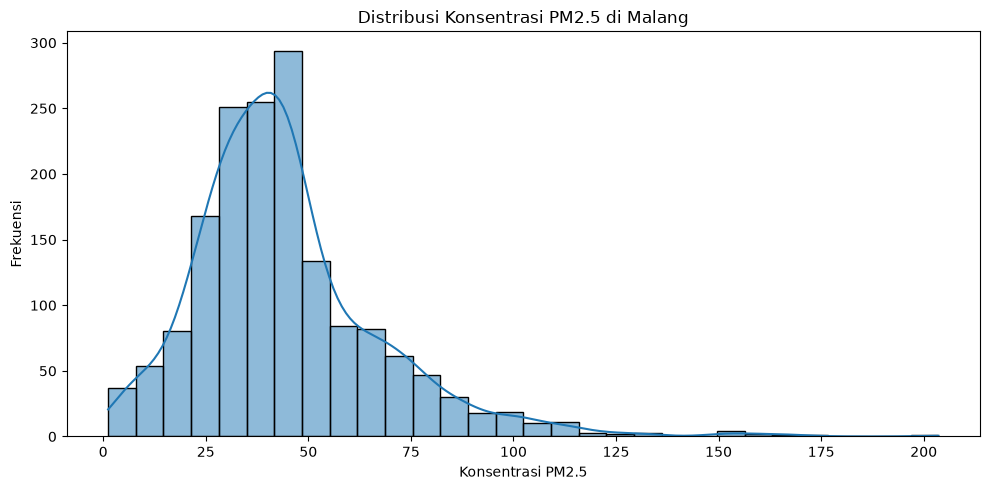

In [57]:

# ============================================================
# 5.2.2 HISTOGRAM DISTRIBUSI PM2.5
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_integrated,
    x="value",
    bins=30,
    kde=True
)

plt.title("Distribusi Konsentrasi PM2.5 di Malang")
plt.xlabel("Konsentrasi PM2.5")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

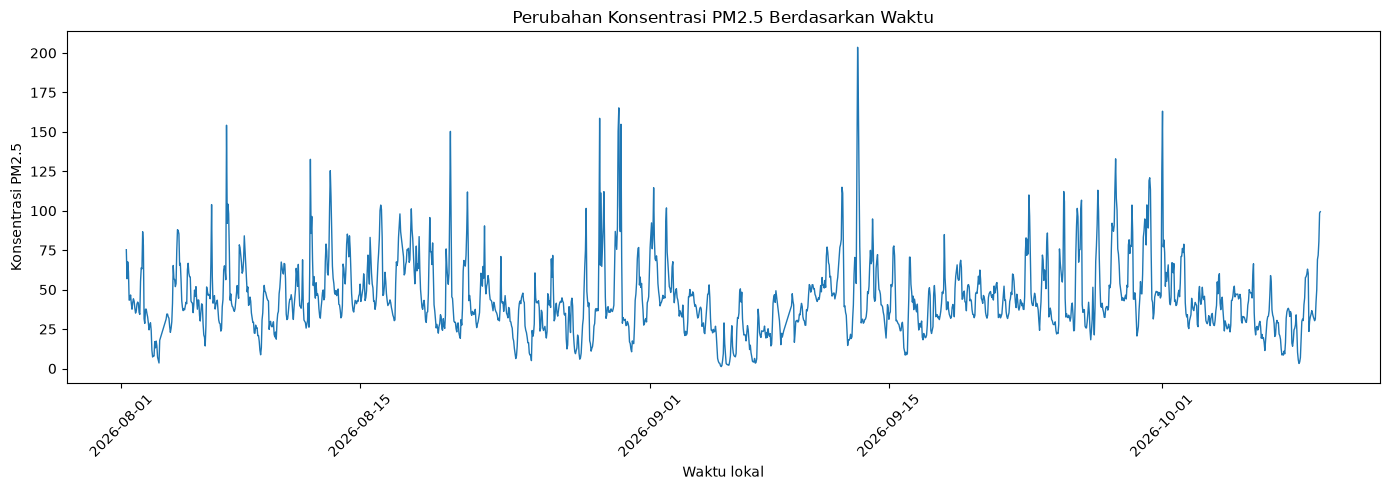

In [58]:

# ============================================================
# 5.2.3 TREN PM2.5 BERDASARKAN WAKTU
# ============================================================

df_tren = df_integrated.sort_values("datetime_local").copy()

plt.figure(figsize=(14, 5))

plt.plot(
    df_tren["datetime_local"],
    df_tren["value"],
    linewidth=1
)

plt.title("Perubahan Konsentrasi PM2.5 Berdasarkan Waktu")
plt.xlabel("Waktu lokal")
plt.ylabel("Konsentrasi PM2.5")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5.3 Rumusan masalah 2 — Hubungan cuaca dengan PM2.5
Bagaimana hubungan antara kondisi cuaca, seperti suhu, kelembapan, curah hujan, dan kecepatan angin, dengan konsentrasi PM2.5 di Malang?

In [59]:

# ============================================================
# 5.3.1 KORELASI VARIABEL CUACA DENGAN PM2.5
# ============================================================

variabel_cuaca = [
    "temperature_c",
    "humidity_percent",
    "precipitation_mm",
    "wind_speed_kmh"
]

kolom_korelasi = ["value"] + variabel_cuaca

korelasi_cuaca = df_integrated[kolom_korelasi].corr(
    method="pearson"
)

print("Matriks korelasi PM2.5 dan variabel cuaca:")
display(korelasi_cuaca)

Matriks korelasi PM2.5 dan variabel cuaca:


,value,temperature_c,humidity_percent,precipitation_mm,wind_speed_kmh
value,1.000000,-0.194835,0.030141,-0.045677,-0.388908
temperature_c,-0.194835,1.000000,-0.877310,0.047862,0.681070
humidity_percent,0.030141,-0.877310,1.000000,0.056048,-0.622239
precipitation_mm,-0.045677,0.047862,0.056048,1.000000,-0.016758
wind_speed_kmh,-0.388908,0.681070,-0.622239,-0.016758,1.000000


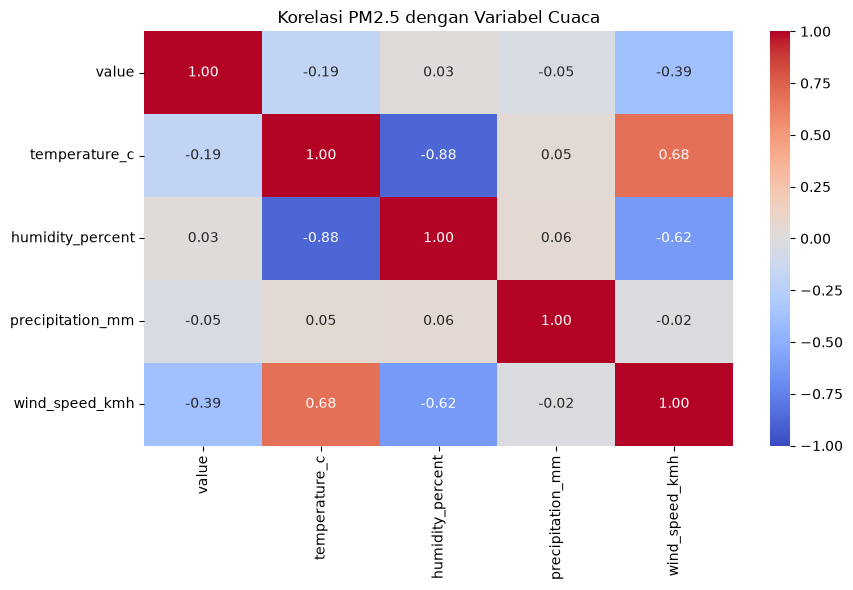

In [60]:

# ============================================================
# 5.3.2 VISUALISASI HEATMAP KORELASI
# ============================================================

plt.figure(figsize=(9, 6))

sns.heatmap(
    korelasi_cuaca,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Korelasi PM2.5 dengan Variabel Cuaca")
plt.tight_layout()
plt.show()

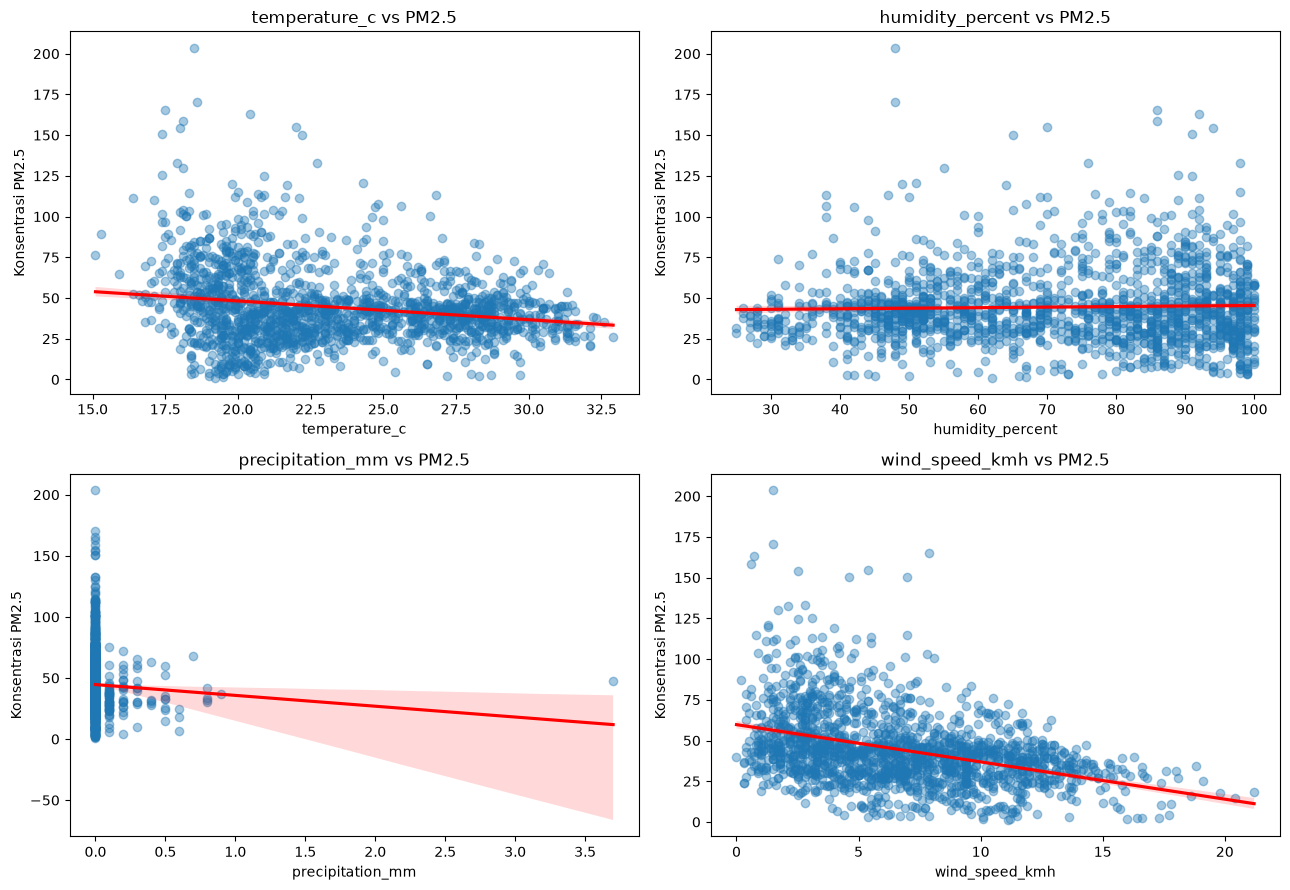

In [61]:

# ============================================================
# 5.3.3 SCATTER PLOT CUACA DAN PM2.5
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, kolom in zip(axes.flat, variabel_cuaca):
    sns.regplot(
        data=df_integrated,
        x=kolom,
        y="value",
        scatter_kws={"alpha": 0.4},
        line_kws={"color": "red"},
        ax=ax
    )

    ax.set_title(f"{kolom} vs PM2.5")
    ax.set_xlabel(kolom)
    ax.set_ylabel("Konsentrasi PM2.5")

plt.tight_layout()
plt.show()

# 5.4 Rumusan masalah 3 — Hubungan hotspot dengan PM2.5
Apakah jumlah deteksi hotspot dalam radius 25 km memiliki hubungan dengan perubahan konsentrasi PM2.5 di Malang?

In [62]:

# ============================================================
# 5.4.1 PERBANDINGAN PM2.5 BERDASARKAN DETEKSI HOTSPOT
# ============================================================

df_integrated["kategori_hotspot"] = np.where(
    df_integrated["hotspot_count"] > 0,
    "Ada hotspot",
    "Tidak ada hotspot"
)

ringkasan_hotspot = (
    df_integrated
    .groupby("kategori_hotspot")["value"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

print("Statistik PM2.5 berdasarkan keberadaan hotspot:")
display(ringkasan_hotspot)

Statistik PM2.5 berdasarkan keberadaan hotspot:


,count,mean,median,min,max,std
kategori_hotspot,,,,,,
Ada hotspot,60,37.65,35.1,2.6,81.4,18.59
Tidak ada hotspot,1592,44.71,41.4,1.2,203.6,23.08


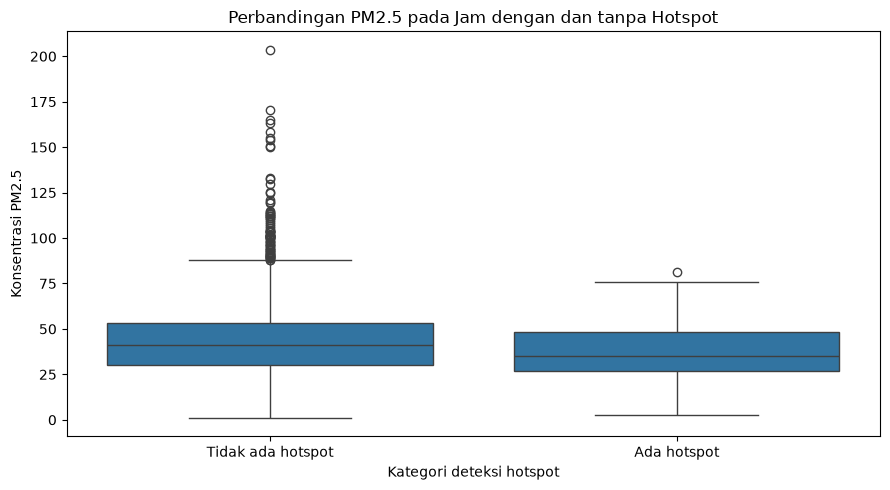

In [63]:

# ============================================================
# 5.4.2 BOXPLOT PM2.5 DAN KATEGORI HOTSPOT
# ============================================================

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_integrated,
    x="kategori_hotspot",
    y="value"
)

plt.title("Perbandingan PM2.5 pada Jam dengan dan tanpa Hotspot")
plt.xlabel("Kategori deteksi hotspot")
plt.ylabel("Konsentrasi PM2.5")
plt.tight_layout()
plt.show()

Korelasi Pearson antara jumlah hotspot dan PM2.5: -0.03


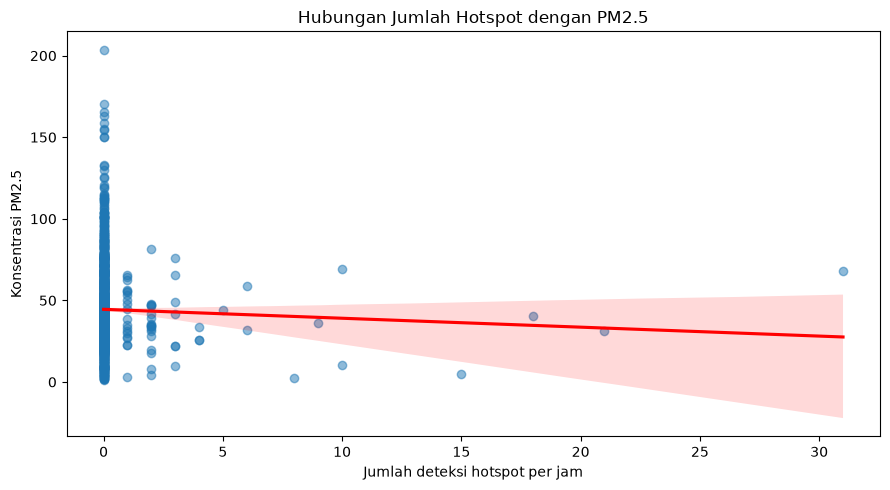

In [64]:

# ============================================================
# 5.4.3 KORELASI JUMLAH HOTSPOT DENGAN PM2.5
# ============================================================

korelasi_hotspot = df_integrated[
    ["value", "hotspot_count"]
].corr(method="pearson").iloc[0, 1]

print(
    "Korelasi Pearson antara jumlah hotspot dan PM2.5:",
    round(korelasi_hotspot, 3)
)

plt.figure(figsize=(9, 5))

sns.regplot(
    data=df_integrated,
    x="hotspot_count",
    y="value",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Hubungan Jumlah Hotspot dengan PM2.5")
plt.xlabel("Jumlah deteksi hotspot per jam")
plt.ylabel("Konsentrasi PM2.5")
plt.tight_layout()
plt.show()

# 6 — Feature Engineering

In [65]:

# ============================================================
# TAHAP 6: FEATURE ENGINEERING
# 6.1 MENYIAPKAN DATASET
# ============================================================

# Membuat salinan agar df_integrated tetap aman
df_ml = df_integrated.copy()

print("=" * 60)
print("PERSIAPAN FEATURE ENGINEERING")
print("=" * 60)

print("\nUkuran dataset awal:")
print(f"Jumlah baris : {df_ml.shape[0]}")
print(f"Jumlah kolom : {df_ml.shape[1]}")

# Memastikan kolom waktu bertipe datetime
df_ml["datetime_local"] = pd.to_datetime(
    df_ml["datetime_local"],
    errors="coerce"
)

# Mengurutkan data berdasarkan waktu
df_ml = df_ml.sort_values(
    by="datetime_local"
).reset_index(drop=True)

# Memeriksa kolom yang diperlukan
kolom_diperlukan = [
    "datetime_local",
    "value",
    "temperature_c",
    "humidity_percent",
    "precipitation_mm",
    "pressure_hpa",
    "wind_speed_kmh",
    "wind_direction_degree",
    "cloud_cover_percent",
    "hotspot_count"
]

kolom_tidak_tersedia = [
    kolom for kolom in kolom_diperlukan
    if kolom not in df_ml.columns
]

if kolom_tidak_tersedia:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {kolom_tidak_tersedia}"
    )

print("\nPemeriksaan kolom berhasil.")
print("Dataset siap diproses.")
display(df_ml.head())

PERSIAPAN FEATURE ENGINEERING

Ukuran dataset awal:
Jumlah baris : 1652
Jumlah kolom : 21

Pemeriksaan kolom berhasil.
Dataset siap diproses.


,id,location_id,latitude,longitude,sensor_id,sensor_name,parameter,unit,value,datetime_utc,...,hour_local,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent,hotspot_count,kategori_hotspot
0,1,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,75.3,2026-08-01 00:00:00,...,2026-08-01 07:00:00,20.2,81.0,0.0,1014.3,1.4,293.0,16.0,0,Tidak ada hotspot
1,2,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,56.9,2026-08-01 01:00:00,...,2026-08-01 08:00:00,22.8,69.0,0.0,1014.3,1.3,90.0,44.0,0,Tidak ada hotspot
2,3,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,67.6,2026-08-01 02:00:00,...,2026-08-01 09:00:00,25.0,63.0,0.0,1013.9,4.3,123.0,91.0,0,Tidak ada hotspot
3,4,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,61.4,2026-08-01 03:00:00,...,2026-08-01 10:00:00,26.3,61.0,0.0,1013.1,6.7,109.0,70.0,0,Tidak ada hotspot
4,5,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,43.3,2026-08-01 04:00:00,...,2026-08-01 11:00:00,27.5,58.0,0.0,1012.1,9.6,95.0,81.0,0,Tidak ada hotspot


In [66]:

# ============================================================
# 6.2 MEMBUAT FITUR WAKTU
# ============================================================

# Fitur jam pengamatan
df_ml["hour"] = df_ml["datetime_local"].dt.hour

# Fitur hari dalam seminggu
# Senin = 0, Minggu = 6
df_ml["day_of_week"] = df_ml["datetime_local"].dt.dayofweek

# Fitur bulan pengamatan
df_ml["month"] = df_ml["datetime_local"].dt.month

# Fitur akhir pekan
df_ml["is_weekend"] = (
    df_ml["day_of_week"] >= 5
).astype(int)

print("Fitur waktu berhasil dibuat:")
display(
    df_ml[
        [
            "datetime_local",
            "hour",
            "day_of_week",
            "month",
            "is_weekend"
        ]
    ].head(10)
)

Fitur waktu berhasil dibuat:


,datetime_local,hour,day_of_week,month,is_weekend
0,2026-08-01 07:00:00,7,5,8,1
1,2026-08-01 08:00:00,8,5,8,1
2,2026-08-01 09:00:00,9,5,8,1
3,2026-08-01 10:00:00,10,5,8,1
4,2026-08-01 11:00:00,11,5,8,1
5,2026-08-01 12:00:00,12,5,8,1
6,2026-08-01 13:00:00,13,5,8,1
7,2026-08-01 14:00:00,14,5,8,1
8,2026-08-01 15:00:00,15,5,8,1
9,2026-08-01 16:00:00,16,5,8,1


In [67]:

# ============================================================
# 6.3 FITUR PM2.5 SATU JAM SEBELUMNYA
# ============================================================

# Membuat fitur sebelumnya berdasarkan urutan waktu
df_ml["previous_datetime"] = (
    df_ml["datetime_local"].shift(1)
)

df_ml["previous_location"] = (
    df_ml["location_id"].shift(1)
)

df_ml["previous_sensor"] = (
    df_ml["sensor_id"].shift(1)
)

df_ml["pm25_previous_hour"] = (
    df_ml["value"].shift(1)
)

# Memastikan jarak waktu tepat satu jam
selisih_waktu = (
    df_ml["datetime_local"] - df_ml["previous_datetime"]
)

kondisi_satu_jam = (
    (selisih_waktu == pd.Timedelta(hours=1))
    & (df_ml["location_id"] == df_ml["previous_location"])
    & (df_ml["sensor_id"] == df_ml["previous_sensor"])
)

df_ml.loc[
    ~kondisi_satu_jam,
    "pm25_previous_hour"
] = np.nan

# Menghapus kolom bantuan
df_ml = df_ml.drop(
    columns=[
        "previous_datetime",
        "previous_location",
        "previous_sensor"
    ]
)

print("Contoh fitur PM2.5 satu jam sebelumnya:")
display(
    df_ml[
        [
            "datetime_local",
            "value",
            "pm25_previous_hour"
        ]
    ].head(15)
)

print(
    "\nJumlah nilai fitur PM2.5 sebelumnya yang kosong:",
    df_ml["pm25_previous_hour"].isna().sum()
)

Contoh fitur PM2.5 satu jam sebelumnya:


,datetime_local,value,pm25_previous_hour
0,2026-08-01 07:00:00,75.3,NaN
1,2026-08-01 08:00:00,56.9,75.3
2,2026-08-01 09:00:00,67.6,56.9
3,2026-08-01 10:00:00,61.4,67.6
4,2026-08-01 11:00:00,43.3,61.4
5,2026-08-01 12:00:00,43.6,43.3
6,2026-08-01 13:00:00,46.6,43.6
7,2026-08-01 14:00:00,41.4,46.6
8,2026-08-01 15:00:00,37.6,41.4
9,2026-08-01 16:00:00,41.8,37.6



Jumlah nilai fitur PM2.5 sebelumnya yang kosong: 7


In [68]:

# ============================================================
# 6.4 MENENTUKAN FITUR DAN TARGET
# ============================================================

fitur_model = [
    "temperature_c",
    "humidity_percent",
    "precipitation_mm",
    "pressure_hpa",
    "wind_speed_kmh",
    "wind_direction_degree",
    "cloud_cover_percent",
    "hotspot_count",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "pm25_previous_hour"
]

target_model = "value"

print("Fitur yang digunakan:")
for nomor, fitur in enumerate(fitur_model, start=1):
    print(f"{nomor}. {fitur}")

print("\nTarget prediksi:")
print(target_model)

Fitur yang digunakan:
1. temperature_c
2. humidity_percent
3. precipitation_mm
4. pressure_hpa
5. wind_speed_kmh
6. wind_direction_degree
7. cloud_cover_percent
8. hotspot_count
9. hour
10. day_of_week
11. month
12. is_weekend
13. pm25_previous_hour

Target prediksi:
value


In [69]:

# ============================================================
# 6.5 PEMERIKSAAN HASIL FEATURE ENGINEERING
# ============================================================

print("=" * 60)
print("HASIL FEATURE ENGINEERING")
print("=" * 60)

print("\nUkuran dataset:")
print(df_ml.shape)

print("\nDaftar kolom:")
print(df_ml.columns.tolist())

print("\nLima data pertama:")
display(df_ml.head())

print("\nJumlah missing values pada fitur:")
display(df_ml[fitur_model].isnull().sum())

print("\nStatistik fitur:")
display(df_ml[fitur_model].describe().T)

HASIL FEATURE ENGINEERING

Ukuran dataset:
(1652, 26)

Daftar kolom:
['id', 'location_id', 'latitude', 'longitude', 'sensor_id', 'sensor_name', 'parameter', 'unit', 'value', 'datetime_utc', 'datetime_local', 'hour_local', 'temperature_c', 'humidity_percent', 'precipitation_mm', 'pressure_hpa', 'wind_speed_kmh', 'wind_direction_degree', 'cloud_cover_percent', 'hotspot_count', 'kategori_hotspot', 'hour', 'day_of_week', 'month', 'is_weekend', 'pm25_previous_hour']

Lima data pertama:


,id,location_id,latitude,longitude,sensor_id,sensor_name,parameter,unit,value,datetime_utc,...,wind_speed_kmh,wind_direction_degree,cloud_cover_percent,hotspot_count,kategori_hotspot,hour,day_of_week,month,is_weekend,pm25_previous_hour
0,1,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,75.3,2026-08-01 00:00:00,...,1.4,293.0,16.0,0,Tidak ada hotspot,7,5,8,1,NaN
1,2,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,56.9,2026-08-01 01:00:00,...,1.3,90.0,44.0,0,Tidak ada hotspot,8,5,8,1,75.3
2,3,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,67.6,2026-08-01 02:00:00,...,4.3,123.0,91.0,0,Tidak ada hotspot,9,5,8,1,56.9
3,4,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,61.4,2026-08-01 03:00:00,...,6.7,109.0,70.0,0,Tidak ada hotspot,10,5,8,1,67.6
4,5,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,µg/m³,43.3,2026-08-01 04:00:00,...,9.6,95.0,81.0,0,Tidak ada hotspot,11,5,8,1,61.4



Jumlah missing values pada fitur:


temperature_c            0
humidity_percent         0
precipitation_mm         0
pressure_hpa             0
wind_speed_kmh           0
wind_direction_degree    0
cloud_cover_percent      0
hotspot_count            0
hour                     0
day_of_week              0
month                    0
is_weekend               0
pm25_previous_hour       7
dtype: int64


Statistik fitur:


,count,mean,std,min,25%,50%,75%,max
temperature_c,1652.0,23.259262,3.886767,15.1,20.000,22.3,26.70,32.9
humidity_percent,1652.0,71.167070,20.419701,25.0,53.000,75.0,89.00,100.0
precipitation_mm,1652.0,0.016949,0.118453,0.0,0.000,0.0,0.00,3.7
pressure_hpa,1652.0,1014.544370,1.754302,1009.4,1013.300,1014.8,1015.80,1018.9
wind_speed_kmh,1652.0,6.687288,3.903909,0.0,3.375,6.2,9.40,21.2
wind_direction_degree,1652.0,182.265738,96.359551,1.0,94.000,188.0,258.00,360.0
cloud_cover_percent,1652.0,44.735472,35.106099,0.0,12.000,38.0,79.25,100.0
hotspot_count,1652.0,0.139225,1.247160,0.0,0.000,0.0,0.00,31.0
hour,1652.0,11.528450,6.940592,0.0,5.000,12.0,18.00,23.0
day_of_week,1652.0,3.032082,1.997166,0.0,1.000,3.0,5.00,6.0


# 7 — Modeling dan Evaluasi

In [70]:

# ============================================================
# TAHAP 7.1: MENYIAPKAN DATA UNTUK MODELING
# ============================================================

# Salin dan urutkan data berdasarkan waktu
df_model = df_ml.copy()

df_model["datetime_local"] = pd.to_datetime(
    df_model["datetime_local"],
    errors="coerce"
)

df_model = df_model.sort_values(
    "datetime_local"
).reset_index(drop=True)

# Target: PM2.5 satu jam berikutnya.
# Target hanya diisi jika pengukuran berikutnya tepat satu jam
# setelah waktu saat ini, pada lokasi dan sensor yang sama.

waktu_berikutnya = df_model["datetime_local"].shift(-1)
lokasi_berikutnya = df_model["location_id"].shift(-1)
sensor_berikutnya = df_model["sensor_id"].shift(-1)
pm25_berikutnya = df_model["value"].shift(-1)

kondisi_target = (
    (waktu_berikutnya - df_model["datetime_local"]
     == pd.Timedelta(hours=1))
    & (lokasi_berikutnya == df_model["location_id"])
    & (sensor_berikutnya == df_model["sensor_id"])
)

df_model["target_pm25_next_hour"] = pm25_berikutnya.where(
    kondisi_target
)

# Fitur untuk model
fitur_model = [
    "temperature_c",
    "humidity_percent",
    "precipitation_mm",
    "pressure_hpa",
    "wind_speed_kmh",
    "wind_direction_degree",
    "cloud_cover_percent",
    "hotspot_count",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "pm25_previous_hour"
]

target_model = "target_pm25_next_hour"

# Mengambil fitur dan target, lalu menghapus baris yang belum lengkap
df_model_final = df_model[
    fitur_model + [target_model, "datetime_local"]
].dropna().copy()

print("=" * 60)
print("PERSIAPAN DATA MODELING")
print("=" * 60)

print("Jumlah baris awal:", len(df_model))
print("Jumlah baris siap modeling:", len(df_model_final))
print("Jumlah fitur:", len(fitur_model))
print("Target:", target_model)

print("\nLima data pertama:")
display(df_model_final.head())

print("\nRentang waktu:")
print("Awal :", df_model_final["datetime_local"].min())
print("Akhir:", df_model_final["datetime_local"].max())

PERSIAPAN DATA MODELING
Jumlah baris awal: 1652
Jumlah baris siap modeling: 1638
Jumlah fitur: 13
Target: target_pm25_next_hour

Lima data pertama:


,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,wind_speed_kmh,wind_direction_degree,cloud_cover_percent,hotspot_count,hour,day_of_week,month,is_weekend,pm25_previous_hour,target_pm25_next_hour,datetime_local
1,22.8,69.0,0.0,1014.3,1.3,90.0,44.0,0,8,5,8,1,75.3,67.6,2026-08-01 08:00:00
2,25.0,63.0,0.0,1013.9,4.3,123.0,91.0,0,9,5,8,1,56.9,61.4,2026-08-01 09:00:00
3,26.3,61.0,0.0,1013.1,6.7,109.0,70.0,0,10,5,8,1,67.6,43.3,2026-08-01 10:00:00
4,27.5,58.0,0.0,1012.1,9.6,95.0,81.0,0,11,5,8,1,61.4,43.6,2026-08-01 11:00:00
5,28.3,53.0,0.0,1011.6,11.4,84.0,90.0,0,12,5,8,1,43.3,46.6,2026-08-01 12:00:00



Rentang waktu:
Awal : 2026-08-01 08:00:00
Akhir: 2026-10-10 06:00:00


# 7.2 Membagi data training dan testing

In [71]:
# Memastikan data terurut berdasarkan waktu
df_model_final = df_model_final.sort_values(
    "datetime_local"
).reset_index(drop=True)

# Menentukan fitur dan target
X = df_model_final[fitur_model]
y = df_model_final[target_model]

# Pembagian 80% data awal untuk training dan 20% data akhir testing
batas = int(len(df_model_final) * 0.8)

X_train = X.iloc[:batas].copy()
X_test = X.iloc[batas:].copy()

y_train = y.iloc[:batas].copy()
y_test = y.iloc[batas:].copy()

print("=" * 60)
print("PEMBAGIAN DATA TRAINING DAN TESTING")
print("=" * 60)

print("Total data :", len(df_model_final))
print("Data training:", len(X_train))
print("Data testing :", len(X_test))

print("\nRentang waktu training:")
print("Awal :", df_model_final["datetime_local"].iloc[0])
print("Akhir:", df_model_final["datetime_local"].iloc[batas - 1])

print("\nRentang waktu testing:")
print("Awal :", df_model_final["datetime_local"].iloc[batas])
print("Akhir:", df_model_final["datetime_local"].iloc[-1])

print("\nUkuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test :", y_test.shape)

PEMBAGIAN DATA TRAINING DAN TESTING
Total data : 1638
Data training: 1310
Data testing : 328

Rentang waktu training:
Awal : 2026-08-01 08:00:00
Akhir: 2026-09-26 14:00:00

Rentang waktu testing:
Awal : 2026-09-26 15:00:00
Akhir: 2026-10-10 06:00:00

Ukuran X_train: (1310, 13)
Ukuran X_test : (328, 13)
Ukuran y_train: (1310,)
Ukuran y_test : (328,)


# 7.3 Melatih dua model Machine Learning

In [72]:

# ============================================================
# TAHAP 7.3: TRAINING LINEAR REGRESSION DAN RANDOM FOREST
# ============================================================

# Model 1: Linear Regression
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# Model 2: Random Forest Regressor
model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

print("Kedua model berhasil dilatih.")
print("1. Linear Regression")
print("2. Random Forest Regressor")

Kedua model berhasil dilatih.
1. Linear Regression
2. Random Forest Regressor


# 7.4 Mengukur performa model

In [73]:

# ============================================================
# TAHAP 7.4: EVALUASI MODEL
# ============================================================

# Prediksi pada data testing
y_pred_lr = model_lr.predict(X_test)
y_pred_rf = model_rf.predict(X_test)

# Fungsi menghitung metrik evaluasi
def evaluasi_model(nama_model, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": nama_model,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

# Membuat tabel perbandingan
hasil_evaluasi = pd.DataFrame([
    evaluasi_model("Linear Regression", y_test, y_pred_lr),
    evaluasi_model("Random Forest Regressor", y_test, y_pred_rf)
])

print("=" * 60)
print("HASIL EVALUASI MODEL")
print("=" * 60)

display(hasil_evaluasi.round(4))

HASIL EVALUASI MODEL


,Model,MAE,RMSE,R2
0,Linear Regression,10.9903,15.8644,0.5537
1,Random Forest Regressor,9.7687,14.7641,0.6135


# 8 — Visualisasi Hasil Prediksi dan Analisis Model

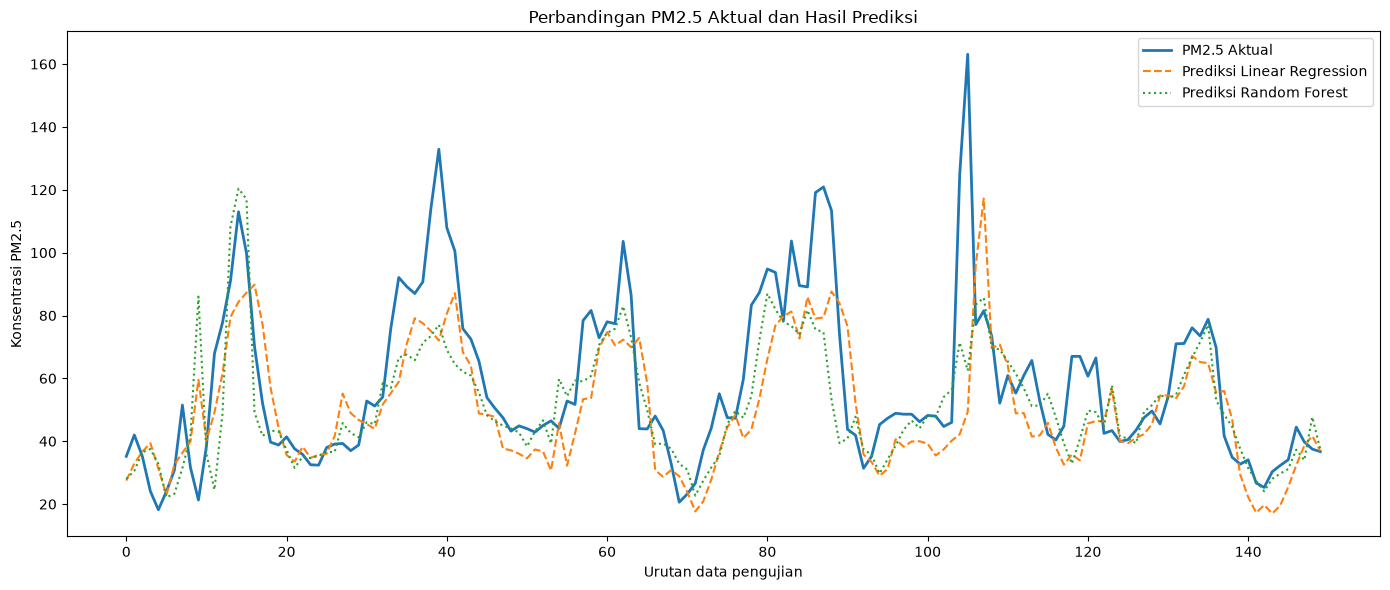

In [74]:

# ============================================================
# TAHAP 8.1: VISUALISASI NILAI AKTUAL VS PREDIKSI
# ============================================================

plt.figure(figsize=(14, 6))

# Menampilkan sebagian data testing agar grafik mudah dibaca
jumlah_tampil = min(150, len(y_test))

plt.plot(
    range(jumlah_tampil),
    y_test.iloc[:jumlah_tampil].to_numpy(),
    label="PM2.5 Aktual",
    linewidth=2
)

plt.plot(
    range(jumlah_tampil),
    y_pred_lr[:jumlah_tampil],
    label="Prediksi Linear Regression",
    linestyle="--"
)

plt.plot(
    range(jumlah_tampil),
    y_pred_rf[:jumlah_tampil],
    label="Prediksi Random Forest",
    linestyle=":"
)

plt.title("Perbandingan PM2.5 Aktual dan Hasil Prediksi")
plt.xlabel("Urutan data pengujian")
plt.ylabel("Konsentrasi PM2.5")
plt.legend()
plt.tight_layout()
plt.show()

# 8.2 Analisis fitur yang paling berpengaruh

Karena Random Forest memperoleh hasil evaluasi lebih baik, kita dapat memeriksa fitur yang paling banyak digunakan model untuk membuat prediksi.

Peringkat fitur berdasarkan Feature Importance:


,Fitur,Importance
12,pm25_previous_hour,0.5156
5,wind_direction_degree,0.1425
0,temperature_c,0.0869
1,humidity_percent,0.0566
4,wind_speed_kmh,0.0534
8,hour,0.0399
3,pressure_hpa,0.0399
6,cloud_cover_percent,0.0338
9,day_of_week,0.0220
10,month,0.0040


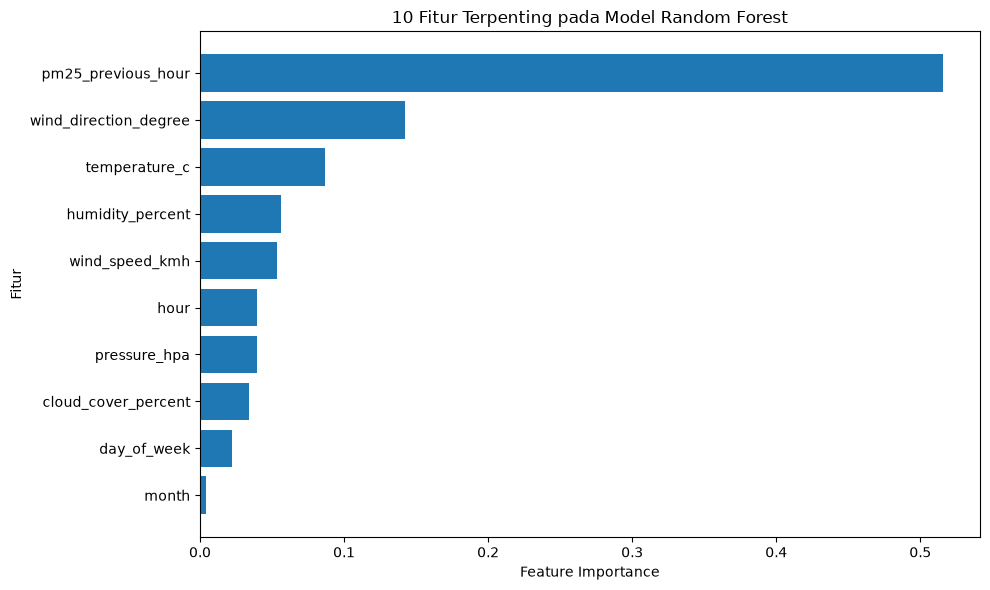

In [75]:
feature_importance = pd.DataFrame({
    "Fitur": fitur_model,
    "Importance": model_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Peringkat fitur berdasarkan Feature Importance:")
display(feature_importance.round(4))

# Visualisasi 10 fitur teratas
top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Fitur"],
    top_features["Importance"]
)

plt.title("10 Fitur Terpenting pada Model Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()